# Notebook 04 — ชุด Holdout การทำภาพให้เป็นมาตรฐาน และการประเมินขั้นสุดท้าย

**วัตถุประสงค์** สำรวจชุด holdout อย่างอิสระ ประเมินความแปรปรวนของภาพจริงและ distribution shift เทียบกับชุดพัฒนา เสนอขั้นตอนการถ่ายภาพที่เป็นมาตรฐาน และทดสอบว่าการทำภาพให้เป็นมาตรฐานด้วยซอฟต์แวร์ช่วยให้แบบจำลองที่ตรึงแล้วทำงานบนข้อมูลใหม่ได้ดีขึ้นหรือไม่ (RQ9, RQ11)

**ลำดับการวิเคราะห์**

| ขั้น | คำถาม | หัวข้อ |
|---|---|---|
| ข้อมูล | ชุด holdout มีอะไร และ annotation ใช้ได้ตามนิยามเดียวกับชุดพัฒนาหรือไม่ | 1–3 |
| ความต่างของโดเมน | ภาพ holdout ต่างจากชุดพัฒนาอย่างไรและมากเพียงใด | 4–5 |
| สมมติฐาน | การถ่ายภาพที่เป็นมาตรฐานและการปรับภาพด้วยซอฟต์แวร์ลดความต่างนั้นได้หรือไม่ | 6 |
| ผลบน holdout | ผลลดลงเท่าใด ระดับภาพถูกต้องเพียงใด ผิดพลาดเพราะอะไร การปรับภาพช่วยหรือไม่ และแบบจำลองมั่นใจผิดที่ใด | 7 |
| การใช้งานจริง | สถานะที่ทำนายบนวิดีโอต่อเนื่องหรือไม่ | 8 |
| สรุป | ข้อค้นพบ ข้อจำกัด และข้อเสนอ | 9 |

**กติกาของ notebook นี้**

1. ใช้แบบจำลองและการตั้งค่าที่ตรึงใน `configs/frozen_inference.yaml` เท่านั้น ไม่ปรับ threshold, preprocessing หรือ augmentation จากผลบน holdout
2. EDA (หัวข้อ 1–5) ไม่ใช้ผลของแบบจำลอง
3. การประเมิน holdout (หัวข้อ 7) รันได้ครั้งเดียว และบันทึกไฟล์ยืนยันการเปิดผล
4. ชุด holdout ทั้งสามชุดเคยถูกประเมินด้วยแบบจำลองของงานเดิมใน notebook 18 จึงไม่ใช่ข้อมูลที่ไม่เคยเห็นโดยสมบูรณ์ งานนี้ไม่ใช้ผลการประเมินเดิมเป็นเกณฑ์ในการตัดสินใจใด ๆ และต้องเปิดเผยข้อเท็จจริงนี้ในวิทยานิพนธ์

## 0. การตั้งค่า

In [1]:
import os, sys, re, json, time, hashlib, platform, subprocess, random, math, shutil, gzip, warnings, contextlib, io
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
warnings.filterwarnings("ignore", message="A single label was found")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "RESEARCH_PLAN.md").exists(), f"ROOT ไม่ถูกต้อง: {ROOT}"
CLASS_NAMES = ["gravel", "sand"]
CLASS_COLORS = {"gravel": "#0072B2", "sand": "#E69F00", "mixed": "#999999", "none": "#DDDDDD"}
STATES = ["none", "gravel", "sand", "mixed"]

# ชุดข้อมูลพัฒนาล่าสุดที่ Notebook 01 บันทึกไว้
VERSIONS = json.loads((ROOT / "manifests" / "dataset_versions.json").read_text())
DEV = VERSIONS[-1]
DEV_DIR = ROOT / "data" / f"dev_{DEV['dev_hash']}"
SILVER_DIR = ROOT / "data" / f"silver_{DEV['silver_hash']}"
MANIFEST = pd.read_csv(ROOT / DEV["manifest"])
assert (DEV_DIR / "data.yaml").exists() and (DEV_DIR / "split_meta.json").exists(), "ต้องรัน Notebook 01 ก่อน"
SPLIT_META = json.loads((DEV_DIR / "split_meta.json").read_text())
# ขอบเขตของ GT ในการประเมิน (protocol "scope"): GT ที่มีพื้นที่ในภาพ letterbox 640 น้อยกว่า 32² px (นิยาม small ของ COCO ที่ขนาดภาพเข้าแบบจำลอง)
# ถูกกำหนดเป็น ignore region ใน val, test และ holdout; ไม่เปลี่ยนป้ายฝึกและไม่ฝึกใหม่ (RESEARCH_PLAN หัวข้อ 15)
EVAL_MIN_PX640 = 32 ** 2

NOTEBOOK = "04_holdout_standardization_and_final_evaluation"
OUT_ROOT = ROOT / "outputs" / "04_holdout"
OUT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "grid.linewidth": 0.5})

def cfg_hash(d, n=10):
    return hashlib.sha256(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:n]

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

def savefig(fig, path_no_ext):
    path_no_ext = Path(path_no_ext); path_no_ext.parent.mkdir(parents=True, exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(f"{path_no_ext}.{ext}", bbox_inches="tight")
    print(f"saved figure: {path_no_ext.relative_to(ROOT)}.png|pdf")

def save_table(df, path, index=False):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    print(f"saved table: {path.relative_to(ROOT)} ({len(df)} rows)")

def split_images(split):
    # คืนรายการภาพของ split พร้อม path ในชุดพัฒนา
    m = MANIFEST[MANIFEST.split == split].copy()
    m["path"] = [str(DEV_DIR / split / "images" / n) for n in m.silver_name]
    m["label_path"] = [str(DEV_DIR / split / "labels" / (Path(n).stem + ".txt")) for n in m.silver_name]
    return m.reset_index(drop=True)

def guard_not_test(paths, allow=False):
    # ป้องกันการโหลดภาพ test ก่อนขั้นประเมินสุดท้าย
    test_dir = str(DEV_DIR / "test")
    bad = [p for p in paths if str(p).startswith(test_dir)]
    if bad and not allow:
        raise PermissionError(f"{len(bad)} test images requested outside the final-evaluation cell")

print("ROOT:", ROOT); print("DEV :", DEV_DIR.relative_to(ROOT), "| silver:", SILVER_DIR.relative_to(ROOT))
print("splits:", SPLIT_META["counts"])

RUN_HOLDOUT_EVAL = True     # เปิดได้ครั้งเดียวหลังผ่านด่าน G5
RUN_TEMPORAL_EVAL = False   # เปิดหลังจากผู้วิจัยยืนยัน label ช่วงเวลา v1
HOLDOUT_ZIPS = {"piled_materials": ROOT.parent / "data" / "bronze" / "holdout" / "Piled Materials.v2i.yolo26.zip",
                "separate_rock_sand": ROOT.parent / "data" / "bronze" / "holdout" / "Separate Rock-Sand.v6i.yolo26.zip",
                "s02": ROOT.parent / "data" / "bronze" / "holdout" / "S02.zip"}
VIDEOS_SRC = ROOT.parent.parent / "experiment" / "data" / "thesis_videos"
FIG = OUT_ROOT / "figures"; TAB = OUT_ROOT / "tables"; FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
FROZEN_PATH = ROOT / "configs" / "frozen_inference.yaml"
print({k: (v.exists(), round(v.stat().st_size / 2**20, 1)) for k, v in HOLDOUT_ZIPS.items()})

ROOT: /home/supawich/Desktop/Aggregate_Project/implement/research
DEV : data/dev_19659e679798 | silver: data/silver_0997f3096843
splits: {'train': 714, 'val': 131, 'test': 244}
{'piled_materials': (True, 86.2), 'separate_rock_sand': (True, 7.9), 's02': (True, 20.7)}


In [2]:
def pkg_version(name):
    try:
        from importlib.metadata import version
        return version(name)
    except Exception:
        return None

def environment_record():
    rec = dict(timestamp=time.strftime("%Y-%m-%dT%H:%M:%S%z"), python=sys.version.split()[0], platform=platform.platform(),
               cpu=platform.processor(), cpu_count=os.cpu_count(),
               packages={p: pkg_version(p) for p in ["torch", "torchvision", "ultralytics", "numpy", "opencv-python",
                                                     "albumentations", "pycocotools", "onnx", "onnxruntime", "openvino",
                                                     "tensorrt", "nncf", "ncnn", "sahi", "scikit-learn", "scikit-image", "thop",
                                                     "ultralytics-thop"]})
    try:
        import torch
        rec["cuda_available"] = torch.cuda.is_available()
        rec["torch_cuda"] = torch.version.cuda
        rec["cudnn"] = torch.backends.cudnn.version()
        if torch.cuda.is_available():
            p = torch.cuda.get_device_properties(0)
            rec["gpu"] = dict(name=p.name, total_memory_gb=round(p.total_memory / 2**30, 2), capability=f"{p.major}.{p.minor}")
    except Exception as e:
        rec["torch_error"] = str(e)
    try:
        rec["nvidia_smi"] = subprocess.check_output(["nvidia-smi", "--query-gpu=name,driver_version,memory.total",
                                                     "--format=csv,noheader"], text=True).strip()
    except Exception:
        rec["nvidia_smi"] = None
    try:
        rec["git_commit"] = subprocess.check_output(["git", "-C", str(ROOT), "rev-parse", "HEAD"], text=True).strip()
    except Exception:
        rec["git_commit"] = None
    return rec

ENV = environment_record()
(OUT_ROOT / "env_manifest.json").write_text(json.dumps(ENV, indent=2))
print(json.dumps(ENV, indent=2))

{
  "timestamp": "2026-10-19T17:01:53+0700",
  "python": "3.12.3",
  "platform": "Linux-7.0.0-38-generic-x86_64-with-glibc2.39",
  "cpu": "x86_64",
  "cpu_count": 20,
  "packages": {
    "torch": "2.14.1",
    "torchvision": "0.29.1",
    "ultralytics": "8.4.180",
    "numpy": "2.5.4",
    "opencv-python": "5.0.0.93",
    "albumentations": "2.0.8",
    "pycocotools": "2.0.11",
    "onnx": "1.23.2",
    "onnxruntime": "1.31.0",
    "openvino": "2026.4.1",
    "tensorrt": null,
    "nncf": null,
    "ncnn": null,
    "sahi": "0.12.8",
    "scikit-learn": "1.9.1",
    "scikit-image": "0.26.0",
    "thop": null,
    "ultralytics-thop": "2.2.2"
  },
  "cuda_available": true,
  "torch_cuda": "13.0",
  "cudnn": 92400,
  "gpu": {
    "name": "NVIDIA GeForce RTX 3080 Ti",
    "total_memory_gb": 11.62,
    "capability": "8.6"
  },
  "nvidia_smi": "NVIDIA GeForce RTX 3080 Ti, 580.178.04, 12288 MiB",
  "git_commit": "3a70169003cd2129868b88aa091d92451c2c6862"
}


### 0.1 ฟังก์ชันสำหรับการประเมินและโมดูล attention

นิยามฟังก์ชันการประเมินแบบ COCO, metric ระดับสถานะ, cluster bootstrap และโมดูล attention ที่ต้องมีก่อนโหลด checkpoint ไว้ในส่วนนี้ เพื่อให้หัวข้อ 1–9 อ่านต่อเนื่องตามลำดับของการวิเคราะห์ ฟังก์ชันเหล่านี้เหมือนกับที่ใช้ใน Notebook 03 และ 03.5 และยังไม่เข้าถึงผลของแบบจำลองบน holdout

In [3]:
# ---------- การประเมินแบบ COCO (pycocotools) พร้อม ignore region และ metric ระดับสถานะ ----------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_util
from ultralytics import YOLO

def load_gt(json_path, protocol="scope"):
    # protocol: "scope" = ignore region ของ Silver และ GT ที่เล็กกว่า EVAL_MIN_PX640 (protocol หลัก); "ignore" = เฉพาะ ignore region ของ Silver;
    # "strict" = นับทุกชิ้นเป็น GT ปกติ
    d = json.loads(Path(json_path).read_text())
    side = {im["id"]: max(im["width"], im["height"]) for im in d["images"]}
    for a in d["annotations"]:
        if protocol == "strict":
            a["iscrowd"] = 0
        elif protocol == "scope" and a["area"] * (640 / side[a["image_id"]]) ** 2 < EVAL_MIN_PX640:
            a["iscrowd"] = 1
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(); gt.dataset = d; gt.createIndex()
    return gt

def predict_dets(weights, records, imgsz=640, conf=0.001, max_det=100, batch=8, transform=None, half=False, desc=""):
    """records: DataFrame with image_id, path, width, height. transform: callable(BGR)->BGR applied before inference."""
    model = YOLO(str(weights))
    dets, t0 = [], time.time()
    recs = records.to_dict("records")
    for k in range(0, len(recs), batch):
        chunk = recs[k:k + batch]
        imgs = [cv2.imread(r["path"]) for r in chunk]
        if transform is not None:
            imgs = [transform(im) for im in imgs]
        res = model.predict(imgs, imgsz=imgsz, conf=conf, max_det=max_det, retina_masks=True, quantize=16 if half else None, verbose=False)
        for r, out in zip(chunk, res):
            if out.masks is None or len(out.boxes) == 0:
                continue
            ms = out.masks.data.cpu().numpy().astype(np.uint8)
            xyxy = out.boxes.xyxy.cpu().numpy(); cls = out.boxes.cls.cpu().numpy().astype(int); sc = out.boxes.conf.cpu().numpy()
            for m, b, c, s in zip(ms, xyxy, cls, sc):
                if m.shape != (r["height"], r["width"]):
                    m = cv2.resize(m, (r["width"], r["height"]), interpolation=cv2.INTER_NEAREST)
                rle = mask_util.encode(np.asfortranarray(m)); rle["counts"] = rle["counts"].decode()
                dets.append(dict(image_id=int(r["image_id"]), category_id=int(c) + 1, score=float(s),
                                 segmentation=rle, bbox=[float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])],
                                 area=float(m.sum())))
    print(f"predicted {len(recs)} images -> {len(dets)} detections in {time.time()-t0:.1f}s {desc}")
    return dets

def cached_dets(cache_file, fn):
    cache_file = Path(cache_file)
    if cache_file.exists():
        with gzip.open(cache_file, "rt") as f:
            return json.load(f)
    dets = fn()
    cache_file.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(cache_file, "wt") as f:
        json.dump(dets, f)
    return dets

def run_cocoeval(gt, dets, iou_type="segm", img_ids=None):
    dts = [dict(d) for d in dets if img_ids is None or d["image_id"] in set(img_ids)]
    if iou_type == "bbox":
        for d in dts:
            d.pop("segmentation", None)
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(dts) if dts else COCO()
        E = COCOeval(gt, dt, iou_type)
        if img_ids is not None:
            E.params.imgIds = sorted(img_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    return E

STAT_NAMES = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR1", "AR10", "AR100", "AR_small", "AR_medium", "AR_large"]

def per_class_ap(E):
    out = {}
    p = E.eval["precision"]  # [T, R, K, A, M]
    for k, cid in enumerate(E.params.catIds):
        pr = p[:, :, k, 0, -1]
        out[CLASS_NAMES[cid - 1]] = dict(AP=float(np.mean(pr[pr > -1])) if (pr > -1).any() else float("nan"),
                                         AP50=float(np.mean(p[0, :, k, 0, -1][p[0, :, k, 0, -1] > -1])) if (p[0, :, k, 0, -1] > -1).any() else float("nan"))
    return out

def image_records(E):
    # ข้อมูลการจับคู่ราย (ภาพ, คลาส) ที่ areaRng='all', maxDet=100 ใช้คำนวณ AP ซ้ำแบบ bootstrap และรายกลุ่ม
    recs = {}
    a_all, md = E.params.areaRng[0], E.params.maxDets[-1]
    for e in E.evalImgs:
        if e is None or e["aRng"] != a_all or e["maxDet"] != md:
            continue
        recs[(e["image_id"], e["category_id"])] = dict(
            scores=np.asarray(e["dtScores"], float), matched=np.asarray(e["dtMatches"]) > 0,
            dt_ig=np.asarray(e["dtIgnore"]).astype(bool), npig=int((np.asarray(e["gtIgnore"]) == 0).sum()))
    return recs

def ap_from_records(recs, img_ids, cat_id, n_iou=10):
    # COCO 101-point interpolated AP จากข้อมูลการจับคู่ (เหมือน COCOeval.accumulate)
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    if not rs:
        return float("nan")
    npig = sum(r["npig"] for r in rs)
    if npig == 0:
        return float("nan")
    scores = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-scores, kind="mergesort")
    M = np.concatenate([r["matched"] for r in rs], axis=1)[:, order]
    IG = np.concatenate([r["dt_ig"] for r in rs], axis=1)[:, order]
    rec_thr = np.linspace(0, 1, 101); aps = []
    for t in range(n_iou):
        tp = np.cumsum(M[t] & ~IG[t]); fp = np.cumsum(~M[t] & ~IG[t])
        rc = tp / npig; pr = tp / np.maximum(tp + fp, np.spacing(1))
        pr = np.maximum.accumulate(pr[::-1])[::-1]
        idx = np.searchsorted(rc, rec_thr, side="left")
        q = np.where(idx < len(pr), pr[np.minimum(idx, len(pr) - 1)], 0.0)
        aps.append(q.mean())
    return float(np.mean(aps))

def operating_point(recs, img_ids, cat_id, iou_index=0, thresholds=None):
    # P/R/F1 ที่ IoU 0.5 สำหรับแต่ละ confidence threshold
    rs = [recs[(i, cat_id)] for i in img_ids if (i, cat_id) in recs]
    npig = sum(r["npig"] for r in rs)
    s = np.concatenate([r["scores"] for r in rs]) if rs else np.zeros(0)
    m = np.concatenate([r["matched"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    ig = np.concatenate([r["dt_ig"][iou_index] for r in rs]) if rs else np.zeros(0, bool)
    thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2) if thresholds is None else np.atleast_1d(thresholds)
    rows = []
    for th in thresholds:
        k = (s >= th) & ~ig
        tp = int((m & k).sum()); fp = int((~m & k).sum()); fn = npig - tp
        p = tp / max(tp + fp, 1); r_ = tp / max(npig, 1); f1 = 2 * p * r_ / max(p + r_, 1e-9)
        rows.append(dict(conf=float(th), TP=tp, FP=fp, FN=fn, precision=p, recall=r_, F1=f1))
    return pd.DataFrame(rows)

def l1_evaluate(gt_json, dets, records, protocol="scope"):
    """Instance-level evaluation: mask and box COCO stats, per-class AP, matching records."""
    gt = load_gt(gt_json, protocol)
    ids = records.image_id.astype(int).tolist()
    out = {}
    for it in ("segm", "bbox"):
        E = run_cocoeval(gt, dets, it, ids)
        out[it] = dict(stats=dict(zip(STAT_NAMES, map(float, E.stats))), per_class=per_class_ap(E), recs=image_records(E))
    # ตรวจว่า AP ที่คำนวณซ้ำตรงกับ COCOeval (ยืนยันความถูกต้องของ ap_from_records)
    for c in (1, 2):
        a1 = ap_from_records(out["segm"]["recs"], ids, c)
        a0 = out["segm"]["per_class"][CLASS_NAMES[c - 1]]["AP"]
        if not (np.isnan(a0) and np.isnan(a1)):
            assert abs(a0 - a1) < 2e-3, f"AP recomputation mismatch for class {c}: {a0} vs {a1}"
    return out

def summarize_l1(res, prefix=""):
    s = {}
    for it, tag in (("segm", "mask"), ("bbox", "box")):
        st = res[it]["stats"]
        s.update({f"{prefix}{tag}_AP": st["AP"], f"{prefix}{tag}_AP50": st["AP50"], f"{prefix}{tag}_AP75": st["AP75"],
                  f"{prefix}{tag}_APs": st["AP_small"], f"{prefix}{tag}_APm": st["AP_medium"], f"{prefix}{tag}_APl": st["AP_large"]})
        for c, v in res[it]["per_class"].items():
            s[f"{prefix}{tag}_AP_{c}"] = v["AP"]
    return s

# ---------- ระดับสถานะ (L2) ----------
STATE_MIN_CONF = 0.05   # ใช้ detection ที่ conf >= ค่านี้ในการคำนวณคะแนนสถานะ (กำหนดล่วงหน้า)

def state_scores(dets, records):
    # S_c = sum(conf * mask_area / image_area) ต่อภาพต่อคลาส
    area = dict(zip(records.image_id.astype(int), records.width * records.height))
    S = defaultdict(lambda: np.zeros(2))
    for d in dets:
        if d["score"] >= STATE_MIN_CONF and d["image_id"] in area:
            S[d["image_id"]][d["category_id"] - 1] += d["score"] * d["area"] / area[d["image_id"]]
    return pd.DataFrame([dict(image_id=i, S_gravel=S[i][0], S_sand=S[i][1]) for i in records.image_id.astype(int)])

def states_from_presence(g, s):
    return np.where(g & s, "mixed", np.where(g, "gravel", np.where(s, "sand", "none")))

def fit_state_thresholds(scores, records):
    # เลือก theta_c บน val เพื่อให้ F1 ของการปรากฏของคลาสสูงสุด
    df = scores.merge(records[["image_id", "state"]], on="image_id")
    out = {}
    for c in CLASS_NAMES:
        y = df.state.isin([c, "mixed"]).values; x = df[f"S_{c}"].values
        cands = np.unique(np.concatenate([[1e-6], np.quantile(x, np.linspace(0, 1, 201))]))
        f1 = []
        for th in cands:
            p = x >= th; tp = (p & y).sum(); fp = (p & ~y).sum(); fn = (~p & y).sum()
            f1.append(2 * tp / max(2 * tp + fp + fn, 1))
        out[c] = float(cands[int(np.argmax(f1))])
    return out

def l2_evaluate(scores, records, thresholds):
    from sklearn.metrics import balanced_accuracy_score, f1_score, cohen_kappa_score, confusion_matrix, average_precision_score
    df = scores.merge(records[["image_id", "state", "group_merged"]], on="image_id")
    pred = states_from_presence(df.S_gravel.values >= thresholds["gravel"], df.S_sand.values >= thresholds["sand"])
    y = df.state.values
    labels = [s for s in STATES if s in set(y) | set(pred)]
    res = dict(n=len(df), balanced_accuracy=float(balanced_accuracy_score(y, pred)),
               macro_f1=float(f1_score(y, pred, average="macro", labels=labels, zero_division=0)),
               kappa=float(cohen_kappa_score(y, pred)), accuracy=float((y == pred).mean()),
               labels=labels, confusion=confusion_matrix(y, pred, labels=labels).tolist())
    for c in CLASS_NAMES:
        yc = df.state.isin([c, "mixed"]).values
        res[f"presence_AP_{c}"] = float(average_precision_score(yc, df[f"S_{c}"])) if yc.any() and (~yc).any() else float("nan")
    df["pred_state"] = pred
    return res, df

# ---------- ช่วงความเชื่อมั่นแบบ cluster bootstrap ----------
def cluster_bootstrap(records, stat_fn, n_boot=1000, seed=SEED, group_col="group_merged"):
    rng = np.random.default_rng(seed)
    groups = records[group_col].unique()
    by_g = {g: records.image_id[records[group_col] == g].astype(int).tolist() for g in groups}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(groups, size=len(groups), replace=True)
        ids = [i for g in pick for i in by_g[g]]
        vals.append(stat_fn(ids))
    vals = np.asarray(vals, float)
    return dict(mean=float(np.nanmean(vals)), ci_low=float(np.nanpercentile(vals, 2.5)), ci_high=float(np.nanpercentile(vals, 97.5)),
                n_boot=n_boot, n_clusters=len(groups))

def bootstrap_mask_ap(res, records, n_boot=1000):
    recs = res["segm"]["recs"]
    def stat(ids):
        return np.nanmean([ap_from_records(recs, ids, c) for c in (1, 2)])
    return cluster_bootstrap(records, stat, n_boot)

In [4]:
# ---------- โมดูล attention และการแทรกเข้า YOLO26 (ต้องนิยามก่อนโหลด checkpoint ที่มี attention) ----------
import torch
import torch.nn as nn
from ultralytics.nn.modules.block import C3k2
from ultralytics.nn.modules.conv import SpatialAttention

ATT_RECORD = {"on": False}   # เก็บค่า attention ล่าสุดเฉพาะตอนทำ visualization (ไม่ให้กระทบการวัด latency)

class ECA(nn.Module):
    """Efficient Channel Attention (Wang et al., CVPR 2020): GAP -> 1D conv (adaptive k) -> sigmoid.
    ปรับให้เริ่มต้นเป็น identity: w = 2*sigmoid(z) และ conv เริ่มที่ศูนย์ (w = 1 ตอนเริ่ม)"""
    def __init__(self, c, gamma=2, b=1):
        super().__init__()
        k = int(abs((math.log2(c) + b) / gamma)); k = k if k % 2 else k + 1
        self.k = k
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.conv.weight)
        self.last_weights = None
    def forward(self, x):
        y = self.pool(x).squeeze(-1).transpose(-1, -2)            # (B, 1, C)
        w = 2 * torch.sigmoid(self.conv(y)).transpose(-1, -2).unsqueeze(-1)  # (B, C, 1, 1)
        if not self.training and ATT_RECORD["on"]:
            self.last_weights = w.detach().float().cpu()
        return x * w

class CBAMPaper(nn.Module):
    """CBAM ตาม Woo et al. (ECCV 2018): channel attention จาก avg-pool และ max-pool ผ่าน MLP ร่วม (reduction r)
    ตามด้วย spatial attention (conv 7x7 บน [mean, max] ตามแกน channel) ปรับให้เริ่มต้นเป็น identity ด้วย 2*sigmoid และ
    น้ำหนักชั้นสุดท้ายเป็นศูนย์"""
    def __init__(self, c, r=16, k=7):
        super().__init__()
        h = max(c // r, 4)
        self.mlp = nn.Sequential(nn.Conv2d(c, h, 1, bias=False), nn.ReLU(inplace=True), nn.Conv2d(h, c, 1, bias=False))
        nn.init.zeros_(self.mlp[2].weight)
        self.spatial = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
        nn.init.zeros_(self.spatial.weight)
        self.last_channel = None; self.last_spatial = None
    def forward(self, x):
        ca = 2 * torch.sigmoid(self.mlp(torch.amax(x, (2, 3), keepdim=True)) + self.mlp(torch.mean(x, (2, 3), keepdim=True)))
        x = x * ca
        sa = 2 * torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        if not self.training and ATT_RECORD["on"]:
            self.last_channel = ca.detach().float().cpu(); self.last_spatial = sa.detach().float().cpu()
        return x * sa

class C3k2Att(C3k2):
    """C3k2 ที่ต่อ attention ไว้ที่ output; ชื่อพารามิเตอร์เดิมของ C3k2 ไม่เปลี่ยน จึงโอน pretrained weights ได้ครบ"""
    def forward(self, x):
        return self.att(super().forward(x))

def insert_attention(seg_model, kind, layers):
    net = seg_model.model
    for i in layers:
        m = net[i]
        assert isinstance(m, C3k2), f"layer {i} is {type(m).__name__}, expected C3k2"
        c = m.cv2.conv.out_channels
        m.__class__ = C3k2Att
        m.att = ECA(c) if kind == "eca" else CBAMPaper(c)
    return seg_model

ATT_SPEC = dict(kind=None, layers=[])
TRANSFER_LOG = []

from ultralytics.models.yolo.segment import SegmentationTrainer
class AttSegTrainer(SegmentationTrainer):
    """สร้างแบบจำลองจาก yaml, แทรก attention ก่อน แล้วจึงโหลด weights (รวมกรณี resume ที่ weights มี attention แล้ว)"""
    def get_model(self, cfg=None, weights=None, verbose=True):
        model = super().get_model(cfg=cfg, weights=None, verbose=False)
        insert_attention(model, ATT_SPEC["kind"], ATT_SPEC["layers"])
        if weights is not None:
            src = (weights.get("ema") or weights["model"]) if isinstance(weights, dict) else weights
            src_sd = src.float().state_dict(); dst_sd = model.state_dict()
            matched = [k for k, v in dst_sd.items() if k in src_sd and src_sd[k].shape == v.shape]
            n_par = sum(dst_sd[k].numel() for k in matched); tot = sum(v.numel() for v in dst_sd.values())
            TRANSFER_LOG.append(dict(kind=ATT_SPEC["kind"], layers=list(ATT_SPEC["layers"]), tensors_matched=len(matched),
                                     tensors_total=len(dst_sd), params_matched=n_par, params_total=tot))
            model.load(weights)
        return model

## 1. การแตกไฟล์และโครงสร้างของชุด holdout

**Method** แตกไฟล์ zip แต่ละชุดไปยัง `data/holdout_raw_<name>/` โดยตรวจว่าไม่มีชื่อไฟล์ที่เป็น path แบบ absolute หรือมี `..` ก่อนแตก บันทึก SHA-256 ของไฟล์ zip อ่าน `data.yaml` และ README ของ Roboflow (ถ้ามี) เพื่อดูชื่อคลาส preprocessing และ augmentation ที่ผู้สร้างชุดข้อมูลใช้

**ตาราง map คลาส (กำหนดก่อนดูผลของแบบจำลอง)**

| ชุดข้อมูล | คลาสในไฟล์ | map เป็น | หมายเหตุ |
|---|---|---|---|
| Piled Materials | Rock | gravel | หินกองเทียบเท่ากับ gravel ของชุดพัฒนา |
| Piled Materials | Sand | sand | |
| Separate Rock-Sand | Rock | gravel | |
| Separate Rock-Sand | Sand | sand | |
| Separate Rock-Sand | Road Cone, Scraper | ตัดออก | ไม่ใช่วัสดุ จึงไม่อยู่ใน GT (prediction ของแบบจำลองบนวัตถุเหล่านี้นับเป็น FP ตามปกติ) |
| S02 | ไม่มี label | — | ใช้วิเคราะห์ภาพและการกระจายของ prediction เท่านั้น |

**Limitation** "Rock" ของชุด holdout อาจมีขนาดเม็ดหรือชนิดต่างจาก gravel ของชุดพัฒนา การ map นี้จึงเป็นสมมติฐานที่ต้องตรวจด้วยตาในหัวข้อ 2

In [5]:
import zipfile
CLASS_MAP = {"piled_materials": {"Rock": 0, "Sand": 1}, "separate_rock_sand": {"Rock": 0, "Sand": 1}}
RAW = {}
for name, z in HOLDOUT_ZIPS.items():
    dst = ROOT / "data" / f"holdout_raw_{name}"
    RAW[name] = dst
    if (dst / "EXTRACTED.json").exists():
        continue
    with zipfile.ZipFile(z) as zf:
        for mem in zf.namelist():
            assert not mem.startswith("/") and ".." not in Path(mem).parts, f"unsafe path in zip: {mem}"
        zf.extractall(dst)
    (dst / "EXTRACTED.json").write_text(json.dumps(dict(zip=str(z), sha256=sha256_file(z), n_members=len(zipfile.ZipFile(z).namelist()),
                                                         extracted=time.strftime("%Y-%m-%dT%H:%M:%S%z")), indent=2))
for name, d in RAW.items():
    print(f"== {name}: {json.loads((d / 'EXTRACTED.json').read_text())['sha256'][:16]}")
    for f in list(d.rglob("data.yaml"))[:1] + list(d.rglob("README*"))[:2]:
        print(f"--- {f.relative_to(d)}"); print(f.read_text(errors="ignore")[:1200])

== piled_materials: ab12d1805e4cee6b
--- data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['Rock', 'Sand']

roboflow:
  workspace: dataset-piled-materials
  project: piled-materials
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/dataset-piled-materials/piled-materials/dataset/2
--- README.roboflow.txt

Piled Materials - v2 2024-11-01 2:38pm

This dataset was exported via roboflow.com on February 27, 2026 at 7:14 AM GMT

Roboflow is an end-to-end computer vision platform that helps you
* collaborate with your team on computer vision projects
* collect & organize images
* understand and search unstructured image data
* annotate, and create datasets
* export, train, and deploy computer vision models
* use active learning to improve your dataset over time

For state of the art Computer Vision training notebooks you can use with this dataset,
visit https://github.com/roboflow/notebooks

To find over 100k other datasets and pre-

In [6]:
import yaml as _yaml
from PIL import Image
rows = []
for name, d in RAW.items():
    yml = list(d.rglob("data.yaml"))
    names = _yaml.safe_load(yml[0].read_text())["names"] if yml else None
    for p in sorted(x for x in d.rglob("*") if x.suffix.lower() in (".jpg", ".jpeg", ".png")):
        lbl = p.parent.parent / "labels" / (p.stem + ".txt") if p.parent.name == "images" else None
        with Image.open(p) as im:
            w, h = im.size
        rows.append(dict(dataset=name, path=str(p), file=p.name, rf_split=p.parent.parent.name if lbl else "unlabeled",
                         label_path=str(lbl) if lbl and lbl.exists() else None, width=w, height=h, sha256=sha256_file(p),
                         class_names=json.dumps(names)))
HO = pd.DataFrame(rows); HO["image_id"] = np.arange(len(HO)) + 100000
save_table(HO.drop(columns=["class_names"]), TAB / "holdout_inventory.csv")
display(HO.groupby(["dataset", "rf_split"]).agg(images=("file", "size"), labelled=("label_path", lambda s: s.notna().sum()),
                                                 sizes=("width", lambda s: ", ".join(sorted({f"{w}x{h}" for w, h in zip(s, HO.loc[s.index, 'height'])})[:4]))))

saved table: outputs/04_holdout/tables/holdout_inventory.csv (1343 rows)


images  labelled               sizes
dataset            rf_split                                       
piled_materials    test          109       109             640x640
                   train         766       766             640x640
                   valid         220       220             640x640
s02                unlabeled      66         0  1280x570, 1920x935
separate_rock_sand test           16        16             640x360
                   train         150       150             640x360
                   valid          16        16             640x360

## 2. ความถูกต้องของ annotation และการใช้กฎ Silver เดียวกับชุดพัฒนา

**Method** ใช้กฎ Silver ที่ตรึงไว้ใน Notebook 01 (`manifests/dataset_versions.json`): ซ่อม geometry, opening ε = 0.25% ของด้านสั้น, รวม annotation ซ้ำ (IoMin ≥ 0.7) ด้วย union, ตัดชิ้นที่เล็กกว่าหนึ่ง cell ของ P3 และกำหนดชิ้นที่พื้นที่ < 0.1% เป็น ignore region จากนั้นสร้าง GT แบบ COCO ของแต่ละชุด ในขั้นประเมิน GT ที่มีพื้นที่ในภาพ letterbox 640 น้อยกว่า 32² px ถูก ignore เพิ่มเติม (protocol scope) เหมือนชุด val และ test

**Rationale** ต้องใช้นิยามของ GT เดียวกับชุดพัฒนา มิฉะนั้นความต่างของผลจะปนกับความต่างของการ annotate

**Limitation** แนวทางการ annotate ของผู้สร้างชุด holdout อาจต่างจากชุดพัฒนา (เช่น วาดทั้งกองเป็นชิ้นเดียว หรือแยกเป็นหลายชิ้น) ซึ่งกฎ Silver แก้ไม่ได้

In [7]:
import shapely
from shapely.geometry import Polygon
from shapely.validation import make_valid
SP = DEV["silver_params"]

def main_polygon(g):
    if g is None or g.is_empty:
        return None
    parts = [p for p in (g.geoms if hasattr(g, "geoms") else [g]) if p.geom_type == "Polygon" and p.area > 0]
    return max(parts, key=lambda p: p.area) if parts else None

def silver_instances(label_path, w, h, cmap, names):
    raw, issues = [], Counter()
    for line in Path(label_path).read_text().splitlines():
        t = line.split()
        if len(t) < 7 or (len(t) - 1) % 2:
            issues["malformed"] += 1; continue
        c = int(t[0]); cname = names[c] if names and c < len(names) else str(c)
        if cname not in cmap:
            issues[f"dropped_class_{cname}"] += 1; continue
        g = Polygon(np.asarray(t[1:], float).reshape(-1, 2) * [w, h])
        if not g.is_valid:
            issues["invalid_geometry"] += 1; g = make_valid(g)
        e = SP["eps_frac"] * min(w, h)
        g = g.buffer(-e, join_style="mitre").buffer(e, join_style="mitre") if e > 0 and not g.is_empty else g
        p = main_polygon(g if g.is_valid else make_valid(g))
        if p is None:
            issues["empty_after_repair"] += 1; continue
        raw.append((cmap[cname], p))
    par = list(range(len(raw)))
    def f(x):
        while par[x] != x:
            par[x] = par[par[x]]; x = par[x]
        return x
    for a in range(len(raw)):
        for b in range(a + 1, len(raw)):
            if raw[a][0] == raw[b][0] and raw[a][1].intersects(raw[b][1]):
                if raw[a][1].intersection(raw[b][1]).area / max(min(raw[a][1].area, raw[b][1].area), 1e-9) >= SP["tau_iomin"]:
                    par[f(a)] = f(b)
    cl = defaultdict(list)
    for a in range(len(raw)):
        cl[f(a)].append(a)
    out = []
    s = 640 / max(w, h); a_floor = SP["a_floor_px640"] / ((w * s) * (h * s))
    for mem in cl.values():
        u = shapely.union_all([raw[m][1] for m in mem]) if len(mem) > 1 else raw[mem[0]][1]
        u = u if u.is_valid else make_valid(u)
        for p in [q for q in (u.geoms if hasattr(u, "geoms") else [u]) if q.geom_type == "Polygon" and q.area > 0]:
            p = Polygon(p.exterior); frac = p.area / (w * h)
            role = "dropped" if frac < a_floor else ("ignore" if frac < SP["a_min_frac"] else "normal")
            out.append(dict(cls=raw[mem[0]][0], geom=p, area_frac=frac, role=role, n_merged=len(mem)))
    return out, issues

SIL_ROWS, ISSUES = [], []
for r in HO[HO.label_path.notna()].itertuples():
    names = json.loads(r.class_names)
    inst, iss = silver_instances(r.label_path, r.width, r.height, CLASS_MAP[r.dataset], names)
    ISSUES.append(dict(dataset=r.dataset, image_id=r.image_id, **iss))
    for k in inst:
        SIL_ROWS.append(dict(dataset=r.dataset, image_id=r.image_id, **k))
HS = pd.DataFrame(SIL_ROWS); HI = pd.DataFrame(ISSUES).fillna(0)
save_table(HI.groupby("dataset").sum(numeric_only=True).drop(columns="image_id").reset_index(), TAB / "holdout_annotation_issues.csv")
display(HI.groupby("dataset").sum(numeric_only=True).drop(columns="image_id"))
display(pd.crosstab([HS.dataset, HS.cls.map(dict(enumerate(CLASS_NAMES)))], HS.role))

saved table: outputs/04_holdout/tables/holdout_annotation_issues.csv (2 rows)


,invalid_geometry,dropped_class_Scraper,dropped_class_Road Cone,malformed
dataset,,,,
piled_materials,0.0,0.0,0.0,0.0
separate_rock_sand,95.0,93.0,199.0,14.0


role                       dropped  ignore  normal
dataset            cls                            
piled_materials    gravel        0       0     528
                   sand          1       0     700
separate_rock_sand gravel        1      33     377
                   sand          5      17     297

In [8]:
def write_coco(dataset):
    sub = HO[(HO.dataset == dataset) & HO.label_path.notna()]
    images, anns, aid = [], [], 1
    for r in sub.itertuples():
        images.append(dict(id=int(r.image_id), file_name=r.file, width=int(r.width), height=int(r.height)))
        for g in HS[(HS.image_id == r.image_id) & (HS.role != "dropped")].itertuples():
            xy = np.asarray(g.geom.exterior.coords)[:-1]; x0, y0, x1, y1 = g.geom.bounds
            anns.append(dict(id=aid, image_id=int(r.image_id), category_id=int(g.cls) + 1, segmentation=[xy.ravel().round(2).tolist()],
                             area=float(g.geom.area), bbox=[x0, y0, x1 - x0, y1 - y0], iscrowd=int(g.role == "ignore")))
            aid += 1
    p = ROOT / "data" / f"holdout_gt_{DEV['silver_hash']}" / f"{dataset}_coco.json"; p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(json.dumps(dict(images=images, annotations=anns, categories=[dict(id=1, name="gravel"), dict(id=2, name="sand")])))
    return p

GT_HO = {d: write_coco(d) for d in CLASS_MAP}
# ป้ายสถานะระดับภาพ (เหมือน Notebook 01)
pres = HS[HS.role == "normal"].groupby(["image_id", "cls"]).area_frac.sum().unstack(fill_value=0).reindex(HO.image_id, fill_value=0)
HO["state"] = [("mixed" if g >= SP["a_min_frac"] and s >= SP["a_min_frac"] else "gravel" if g >= SP["a_min_frac"] else "sand" if s >= SP["a_min_frac"] else "none")
               for g, s in zip(pres.get(0, 0), pres.get(1, 0))]
HO.loc[HO.label_path.isna(), "state"] = "unlabeled"
display(pd.crosstab(HO.dataset, HO.state))
print({k: str(v.relative_to(ROOT)) for k, v in GT_HO.items()})

state,gravel,mixed,none,sand,unlabeled
dataset,,,,,
piled_materials,430,49,40,576,0
s02,0,0,0,0,66
separate_rock_sand,4,175,1,2,0


{'piled_materials': 'data/holdout_gt_0997f3096843/piled_materials_coco.json', 'separate_rock_sand': 'data/holdout_gt_0997f3096843/separate_rock_sand_coco.json'}


## 3. ภาพซ้ำภายในชุด holdout และการซ้อนทับกับชุดพัฒนา

**Method** ตรวจภาพซ้ำแท้ (SHA-256) และภาพเกือบซ้ำ (pHash d ≤ 8 ซึ่งเป็นเกณฑ์เดียวกับ Notebook 01) ทั้งภายในแต่ละชุด holdout และระหว่าง holdout กับชุดพัฒนา ภาพเกือบซ้ำภายในชุดเดียวกันรวมเป็น cluster ซึ่งใช้เป็นหน่วยของ cluster bootstrap ในหัวข้อ 7

**Rationale** Roboflow export อาจมีภาพ augment หลายเวอร์ชันของภาพต้นฉบับเดียวกัน (ตรวจจาก README) ถ้านับเป็นภาพอิสระ ช่วงความเชื่อมั่นจะแคบเกินจริง และถ้ามีภาพซ้อนทับกับชุดพัฒนา ผลบน holdout จะสูงเกินจริง

**Reference** Barz & Denzler (2020), *Journal of Imaging* 6(6): 41

In [9]:
import imagehash
def phash(path):
    with Image.open(path) as im:
        return np.asarray(imagehash.phash(im.convert("L"), hash_size=8).hash, bool).ravel()
H_ho = np.stack([phash(p) for p in HO.path])
DEVALL = MANIFEST.assign(path=[str(SILVER_DIR / "images" / n) for n in MANIFEST.silver_name])
H_dev = np.stack([phash(p) for p in DEVALL.path])
D_hh = (H_ho[:, None, :] != H_ho[None, :, :]).sum(2); np.fill_diagonal(D_hh, 99)
D_hd = (H_ho[:, None, :] != H_dev[None, :, :]).sum(2)
D_ND = int(DEV.get("near_dup_threshold", 8))
HO["exact_dup_in_dev"] = HO.sha256.isin(set(MANIFEST.sha256))
HO["min_dist_to_dev"] = D_hd.min(1)
par = list(range(len(HO)))
def fnd(x):
    while par[x] != x:
        par[x] = par[par[x]]; x = par[x]
    return x
for i, j in zip(*np.where(np.triu(D_hh <= D_ND, 1))):
    if HO.dataset.iloc[i] == HO.dataset.iloc[j]:
        par[fnd(i)] = fnd(j)
HO["cluster"] = [f"{HO.dataset.iloc[i][:4]}_{fnd(i)}" for i in range(len(HO))]
ov = HO.groupby("dataset").agg(images=("file", "size"), clusters=("cluster", "nunique"), exact_dup_in_dev=("exact_dup_in_dev", "sum"),
                                near_dup_to_dev=("min_dist_to_dev", lambda s: int((s <= D_ND).sum())), min_dist_to_dev=("min_dist_to_dev", "min"))
save_table(ov.reset_index(), TAB / "holdout_duplicates_and_overlap.csv"); display(ov)

saved table: outputs/04_holdout/tables/holdout_duplicates_and_overlap.csv (3 rows)


,images,clusters,exact_dup_in_dev,near_dup_to_dev,min_dist_to_dev
dataset,,,,,
piled_materials,1095,1031,0,0,12
s02,66,2,0,0,20
separate_rock_sand,182,96,0,0,14


## 4. สถิติของภาพและ distribution shift เทียบกับชุดพัฒนา

**Method**

1. คำนวณสถิติชุดเดียวกับ Notebook 01 (L\* เฉลี่ย, RMS contrast, a\*, b\*, saturation, colourfulness, ความแปรปรวนของ Laplacian ที่ด้านสั้น 360 พิกเซล) แล้ววัดระยะห่างของการกระจายระหว่างชุดพัฒนา (train) กับ holdout แต่ละชุดด้วย Wasserstein distance (หน่วยเดียวกับสถิติ) และ Kolmogorov–Smirnov statistic
2. Domain classifier: ใช้ embedding จาก YOLO26n-seg ที่ pretrain บน COCO (ไม่ใช่แบบจำลองที่ฝึกแล้ว) ฝึก logistic regression แยกภาพชุดพัฒนาออกจากภาพ holdout ด้วย grouped CV 5 fold (กลุ่ม = กลุ่มวิดีโอของชุดพัฒนา และ cluster ของ holdout) ค่า AUC ใกล้ 0.5 แปลว่าแยกไม่ออก ส่วนค่าใกล้ 1 แปลว่ามี shift ชัดเจน

**Reference** การวัด shift ด้วยตัวจำแนกโดเมนเป็นแนวทางที่ใช้แพร่หลาย (เช่น Rabanser et al., 2019, "Failing Loudly", *NeurIPS* [รอตรวจ]); WILDS (Koh et al., 2021, *ICML*) เป็นตัวอย่างของ benchmark ที่วัดผลภายใต้ distribution shift [รอตรวจ]

**Limitation** AUC สูงบอกว่ามี shift แต่ไม่บอกว่า shift นั้นทำให้ประสิทธิภาพลดลงหรือไม่ ซึ่งต้องดูจากผลในหัวข้อ 7

saved table: outputs/04_holdout/tables/distribution_shift_stats.csv (24 rows)


dataset,piled_materials,s02,separate_rock_sand
stat,,,
L_mean,13.558,28.880,21.892
L_std,1.727,2.973,2.265
a_mean,2.185,1.329,0.434
b_mean,6.665,3.015,2.452
clip_frac,0.055,0.052,0.043
colorfulness,14.748,18.763,8.182
lap_var,748.153,1100.240,2200.308
sat_mean,0.127,0.028,0.010


saved figure: outputs/04_holdout/figures/fig01_shift_image_stats.png|pdf


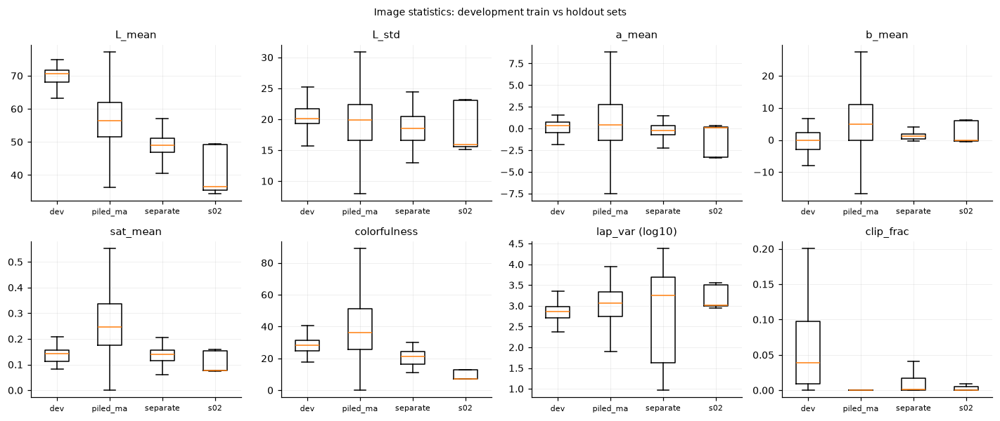

In [10]:
from scipy.stats import wasserstein_distance, ks_2samp
def image_stats(path, short=360):
    bgr = cv2.imread(path)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    L = lab[..., 0] * 100 / 255; a = lab[..., 1] - 128; b = lab[..., 2] - 128
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV); rgb = bgr[..., ::-1].astype(np.float32)
    rg = rgb[..., 0] - rgb[..., 1]; yb = 0.5 * (rgb[..., 0] + rgb[..., 1]) - rgb[..., 2]
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY); s = short / min(g.shape)
    gs = cv2.resize(g, (round(g.shape[1] * s), round(g.shape[0] * s)), interpolation=cv2.INTER_AREA)
    return dict(L_mean=L.mean(), L_std=L.std(), a_mean=a.mean(), b_mean=b.mean(), sat_mean=hsv[..., 1].mean() / 255,
                colorfulness=np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()),
                lap_var=cv2.Laplacian(gs, cv2.CV_64F).var(), clip_frac=float(((g == 0) | (g == 255)).mean()))
STAT_COLS = ["L_mean", "L_std", "a_mean", "b_mean", "sat_mean", "colorfulness", "lap_var", "clip_frac"]
TR = split_images("train")
DS = pd.DataFrame([image_stats(p) for p in TR.path]).assign(dataset="dev_train")
HS_ = pd.DataFrame([image_stats(p) for p in HO.path]).assign(dataset=HO.dataset.values, image_id=HO.image_id.values)
for c in STAT_COLS:
    HO[c] = HS_[c].values
shift = []
for d in HO.dataset.unique():
    for c in STAT_COLS:
        x, y = DS[c].values, HO.loc[HO.dataset == d, c].values
        shift.append(dict(dataset=d, stat=c, dev_median=np.median(x), holdout_median=np.median(y), wasserstein=wasserstein_distance(x, y),
                          ks=ks_2samp(x, y).statistic))
SHIFT = pd.DataFrame(shift); save_table(SHIFT, TAB / "distribution_shift_stats.csv")
display(SHIFT.pivot(index="stat", columns="dataset", values="wasserstein").round(3))
fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, c in zip(axes.ravel(), STAT_COLS):
    data = [np.log10(DS[c] + 1e-6) if c == "lap_var" else DS[c]] + [np.log10(HO.loc[HO.dataset == d, c] + 1e-6) if c == "lap_var" else HO.loc[HO.dataset == d, c] for d in HO.dataset.unique()]
    ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, len(data) + 1), ["dev"] + [d[:8] for d in HO.dataset.unique()], fontsize=7)
    ax.set_title(c + (" (log10)" if c == "lap_var" else ""))
fig.suptitle("Image statistics: development train vs holdout sets", fontsize=9); fig.tight_layout(); savefig(fig, FIG / "fig01_shift_image_stats"); plt.show()

In [11]:
import torch
from ultralytics import YOLO
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
emb_model = YOLO(str(ROOT / "weights" / "yolo26n-seg.pt"))
def embed(paths):
    out = []
    for k in range(0, len(paths), 32):
        out += [e.float().cpu().numpy().ravel() for e in emb_model.embed(list(paths[k:k + 32]), imgsz=640, verbose=False)]
    E = np.stack(out); return E / np.linalg.norm(E, axis=1, keepdims=True)
E_dev = embed(TR.path.tolist()); E_ho = embed(HO.path.tolist())
auc_rows = []
for d in HO.dataset.unique():
    m = (HO.dataset == d).values
    X = np.vstack([E_dev, E_ho[m]]); y = np.r_[np.zeros(len(E_dev)), np.ones(m.sum())]
    groups = np.r_[TR.group_merged.values, HO.cluster.values[m]]
    probs = np.zeros(len(y))
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, groups):
        clf = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced").fit(X[tr], y[tr]); probs[te] = clf.predict_proba(X[te])[:, 1]
    auc_rows.append(dict(dataset=d, n_dev=len(E_dev), n_holdout=int(m.sum()), domain_classifier_auc=roc_auc_score(y, probs)))
AUC = pd.DataFrame(auc_rows); save_table(AUC, TAB / "domain_classifier_auc.csv"); display(AUC.round(3))

saved table: outputs/04_holdout/tables/domain_classifier_auc.csv (3 rows)


,dataset,n_dev,n_holdout,domain_classifier_auc
0,piled_materials,714,1095,1.0
1,separate_rock_sand,714,182,1.0
2,s02,714,66,1.0


## 5. ตัวอย่างภาพและกรณียากของชุด holdout

**Method** แสดงตัวอย่างของแต่ละชุดพร้อม GT ที่ผ่านกฎ Silver และกรณียากที่เลือกด้วยเกณฑ์เดียวกับ Notebook 01 (มืดที่สุด, คมชัดน้อยที่สุด, instance เล็กมากที่สุด)

saved figure: outputs/04_holdout/figures/fig02_samples_piled_materials.png|pdf


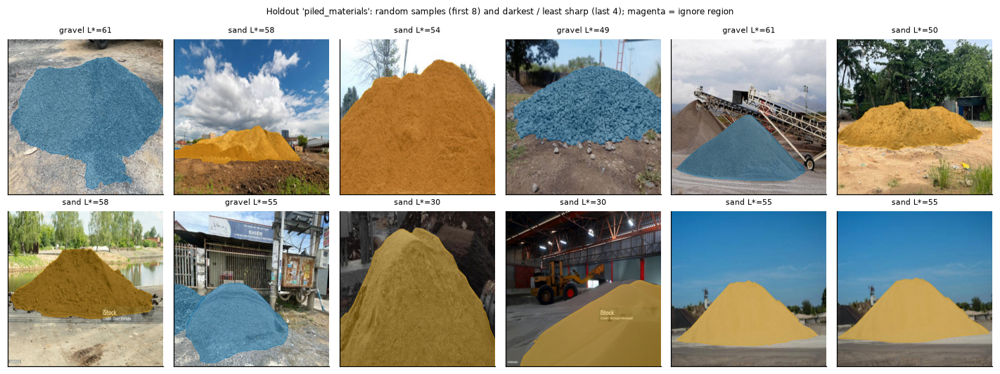

saved figure: outputs/04_holdout/figures/fig02_samples_separate_rock_sand.png|pdf


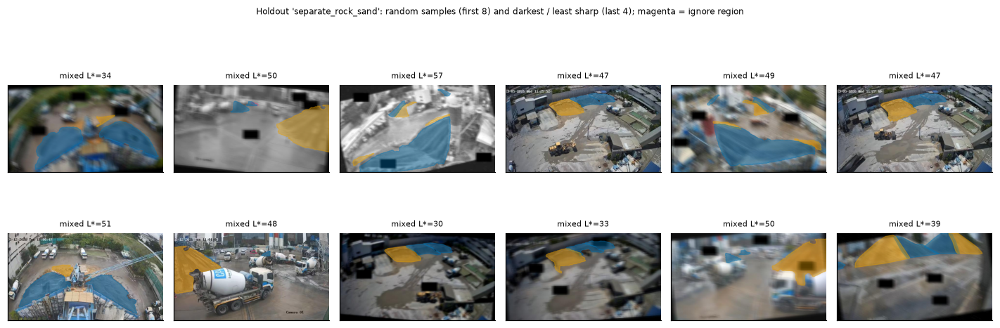

saved figure: outputs/04_holdout/figures/fig02_samples_s02.png|pdf


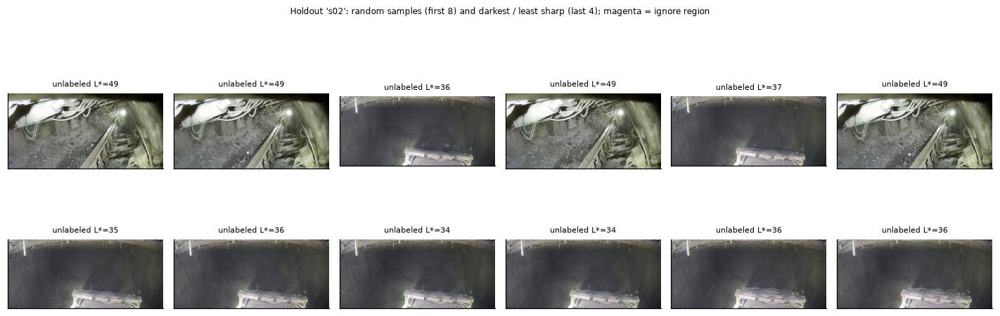

In [12]:
def draw_gt(ax, iid, img):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for g in HS[(HS.image_id == iid) & (HS.role != "dropped")].itertuples():
        col = CLASS_COLORS[CLASS_NAMES[g.cls]]
        ax.add_patch(MplPolygon(np.asarray(g.geom.exterior.coords), facecolor=col if g.role == "normal" else "none", alpha=0.4,
                                edgecolor=col if g.role == "normal" else "#EE3377", lw=0.8))

for d in HO.dataset.unique():
    sub = HO[HO.dataset == d]
    pick = sub.sample(min(8, len(sub)), random_state=SEED).image_id.tolist()
    hard = (sub.nsmallest(2, "L_mean").image_id.tolist() + sub.nsmallest(2, "lap_var").image_id.tolist())
    ids = list(dict.fromkeys(pick + hard))[:12]
    fig, axes = plt.subplots(2, 6, figsize=(13, 5))
    for ax, iid in zip(axes.ravel(), ids):
        r = HO[HO.image_id == iid].iloc[0]; draw_gt(ax, iid, cv2.imread(r.path))
        ax.set_title(f"{r.state} L*={r.L_mean:.0f}", fontsize=7)
    for ax in axes.ravel()[len(ids):]:
        ax.axis("off")
    fig.suptitle(f"Holdout '{d}': random samples (first 8) and darkest / least sharp (last 4); magenta = ignore region", fontsize=8)
    fig.tight_layout(); savefig(fig, FIG / f"fig02_samples_{d}"); plt.show()

## 6. การถ่ายภาพที่เป็นมาตรฐานและการทำภาพให้เป็นมาตรฐานด้วยซอฟต์แวร์

### 6.1 ข้อเสนอขั้นตอนการถ่ายภาพที่เป็นมาตรฐาน (physical acquisition)

ส่วนนี้แยกจากการปรับภาพด้วยซอฟต์แวร์ เพราะการปรับภาพไม่สามารถกู้ข้อมูลที่ไม่ได้บันทึกไว้ เช่น รายละเอียดในบริเวณที่สว่างจนตัดปลาย หรือเนื้อผิวที่หายไปจากการเบลอ

| องค์ประกอบ | ข้อเสนอ | การตรวจสอบ |
|---|---|---|
| แสง | ติดตั้งแหล่งแสงเสริมแบบกระจายแสงที่ตำแหน่งคงที่ เพื่อลดผลของแสงอาทิตย์และเงาของโครงสร้าง; วัดความสว่างของฉาก (lux) ที่จุดเทวัสดุในแต่ละช่วงเวลา | บันทึกค่า lux ต่อครั้ง; ตรวจ L\* เฉลี่ยของภาพอยู่ในช่วงที่กำหนด |
| Exposure | ล็อก exposure และ gain (ไม่ใช้ auto exposure) หรือจำกัดช่วงของ auto exposure | สัดส่วนพิกเซลที่ตัดปลาย (0 หรือ 255) ต่ำกว่าเกณฑ์ |
| White balance และสี | ล็อก white balance และติดแผ่นเทียบสี (เช่น ColorChecker 24 สี) ในมุมของภาพที่ไม่ถูกวัสดุบัง เพื่อใช้ปรับเทียบสีด้วย matrix 3×3 จากแผ่นเทียบสี | ΔE2000 ของแผ่นเทียบสีหลังปรับเทียบต่ำกว่าเกณฑ์ |
| ความละเอียดและเรขาคณิต | ความละเอียดอย่างน้อย 1280 × 720, ระยะทำงาน มุมกล้อง และการวางแนว (แนวตั้งหรือแนวนอน) คงที่ระหว่างจุดติดตั้ง; ติดกล้องบนฐานที่ไม่สั่น | ตรวจตำแหน่งของจุดอ้างอิงในภาพ (เช่น ขอบตะแกรง) ไม่เลื่อนเกินเกณฑ์ |
| ความคมชัด | ตั้งโฟกัสคงที่ที่ระยะของกองวัสดุ; shutter speed ที่สั้นพอสำหรับวัสดุที่กำลังตก | ความแปรปรวนของ Laplacian สูงกว่าเปอร์เซ็นไทล์ที่ 5 ของชุดพัฒนา |
| การบีบอัด | บันทึกวิดีโอที่ bitrate สูง หรือเก็บเฟรมเป็น JPEG คุณภาพ ≥ 90 | ตรวจ blocking artifact |
| สภาพแวดล้อม | บันทึกสภาพอากาศ (ฝน ฝุ่น) และเวลาของการบันทึกเป็น metadata | ใช้แยกวิเคราะห์ผลตามสภาพแวดล้อม |

**Reference** แนวทางการวัดคุณลักษณะกล้องของ EMVA Standard 1288 [รอตรวจ]; การปรับเทียบสีด้วยแผ่นเทียบสี (McCamy et al., 1976, ColorChecker) [รอตรวจ]

### 6.2 การทำภาพให้เป็นมาตรฐานด้วยซอฟต์แวร์ที่ทำได้กับข้อมูลที่มี

ภาพของชุดพัฒนาและ holdout ไม่มีแผ่นเทียบสี ข้อมูล exposure หรือข้อมูลแสง จึง**ไม่สามารถอ้างว่าภาพผ่านการปรับเทียบ (calibrate)** สิ่งที่ทำได้คือทำให้สถิติของภาพใกล้กับชุดพัฒนา ด้วยขั้นตอนที่กำหนดล่วงหน้าและใช้พารามิเตอร์จากชุดพัฒนาเท่านั้น

| ขั้นตอน | รหัส | การทำงาน |
|---|---|---|
| ภาพดิบ | S0 | ไม่ปรับ (เป็นการตั้งค่าที่ตรึงไว้ ถ้า Notebook 02 ไม่ได้เลือก preprocessing ใด) |
| มาตรฐานด้วยสถิติของชุดพัฒนา | S1 | gray-world white balance แล้วปรับ gamma ให้ L\* เฉลี่ยเท่ากับ median ของ train ในชุดพัฒนา |

**การตรวจคุณภาพภาพก่อนเข้าระบบ (image-quality gate)** ใช้เกณฑ์จากชุดพัฒนา: มืดเกิน (L\* เฉลี่ยต่ำกว่าเปอร์เซ็นไทล์ที่ 1 ของ train), ตัดปลายเกิน (สัดส่วนพิกเซลที่ตัดปลายสูงกว่าเปอร์เซ็นไทล์ที่ 99), เบลอ (ความแปรปรวนของ Laplacian ต่ำกว่าเปอร์เซ็นไทล์ที่ 1) และสีเอน (|a\*| หรือ |b\*| เกินเปอร์เซ็นไทล์ที่ 99) รายงานสัดส่วนภาพที่ไม่ผ่านของแต่ละชุด และผลของแบบจำลองแยกตามภาพที่ผ่านและไม่ผ่าน

**Limitation** S1 อาจทำให้สีที่เป็นลักษณะของวัสดุเปลี่ยนไป (เช่น ทรายถูกดึงเข้าหาสีเทาเมื่อเต็มภาพ) ผลลบของ S1 จึงเป็นไปได้และต้องรายงานตามจริง

In [13]:
TARGET_L = float(DS.L_mean.median())
def std_grayworld(img):
    f = img.astype(np.float32); m = f.reshape(-1, 3).mean(0)
    return np.clip(f * (m.mean() / np.maximum(m, 1e-6)), 0, 255).astype(np.uint8)
def std_gamma(img, target=TARGET_L):
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0].mean() / 255
    g = np.log(target / 100) / np.log(max(min(L, 0.99), 0.01))
    return cv2.LUT(img, ((np.arange(256) / 255.0) ** g * 255).clip(0, 255).astype(np.uint8))
def standardize_S1(img):
    return std_gamma(std_grayworld(img))
STANDARD = {"S0_raw": None, "S1_dev_stats": standardize_S1}

qthr = dict(L_low=np.percentile(DS.L_mean, 1), clip_high=np.percentile(DS.clip_frac, 99), lap_low=np.percentile(DS.lap_var, 1),
            a_abs=np.percentile(np.abs(DS.a_mean), 99), b_abs=np.percentile(np.abs(DS.b_mean), 99))
HO["qc_dark"] = HO.L_mean < qthr["L_low"]; HO["qc_clipped"] = HO.clip_frac > qthr["clip_high"]
HO["qc_blur"] = HO.lap_var < qthr["lap_low"]; HO["qc_cast"] = (HO.a_mean.abs() > qthr["a_abs"]) | (HO.b_mean.abs() > qthr["b_abs"])
HO["qc_pass"] = ~(HO.qc_dark | HO.qc_clipped | HO.qc_blur | HO.qc_cast)
QC = HO.groupby("dataset")[["qc_dark", "qc_clipped", "qc_blur", "qc_cast", "qc_pass"]].mean()
save_table(QC.reset_index(), TAB / "image_quality_gate.csv"); print("thresholds from dev train:", {k: round(float(v), 3) for k, v in qthr.items()}); display(QC.round(3))

saved table: outputs/04_holdout/tables/image_quality_gate.csv (3 rows)
thresholds from dev train: {'L_low': 62.728, 'clip_high': 0.186, 'lap_low': 235.443, 'a_abs': 1.659, 'b_abs': 7.767}


,qc_dark,qc_clipped,qc_blur,qc_cast,qc_pass
dataset,,,,,
piled_materials,0.782,0.021,0.067,0.694,0.06
s02,1.000,0.000,0.000,0.394,0.00
separate_rock_sand,1.000,0.000,0.368,0.088,0.00


saved figure: outputs/04_holdout/figures/fig03_standardization_piled_materials.png|pdf


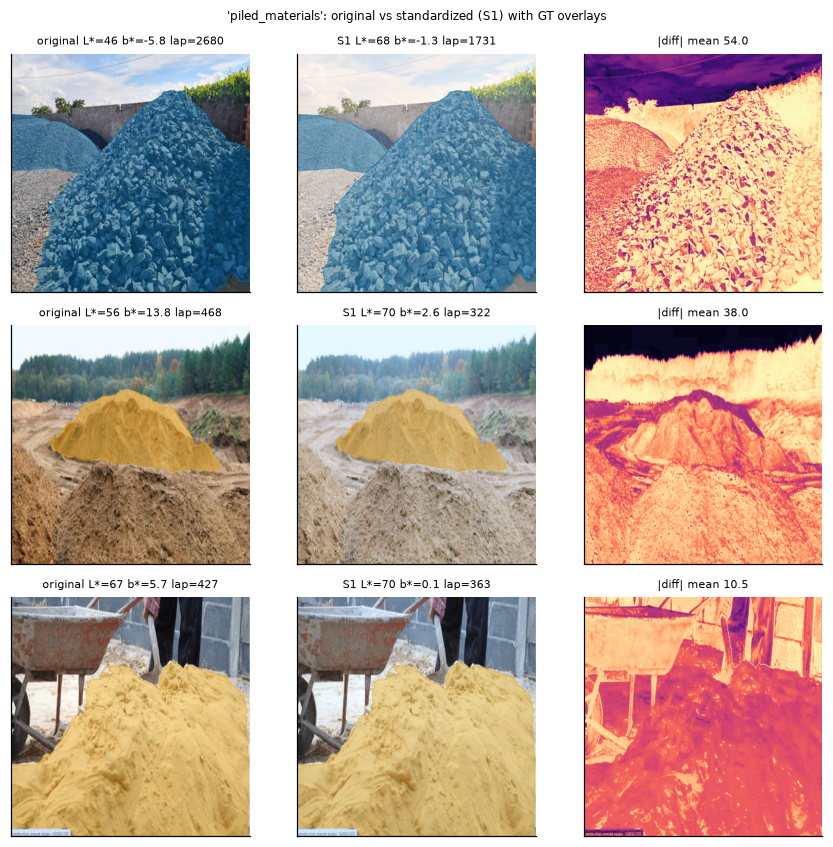

saved figure: outputs/04_holdout/figures/fig03_standardization_separate_rock_sand.png|pdf


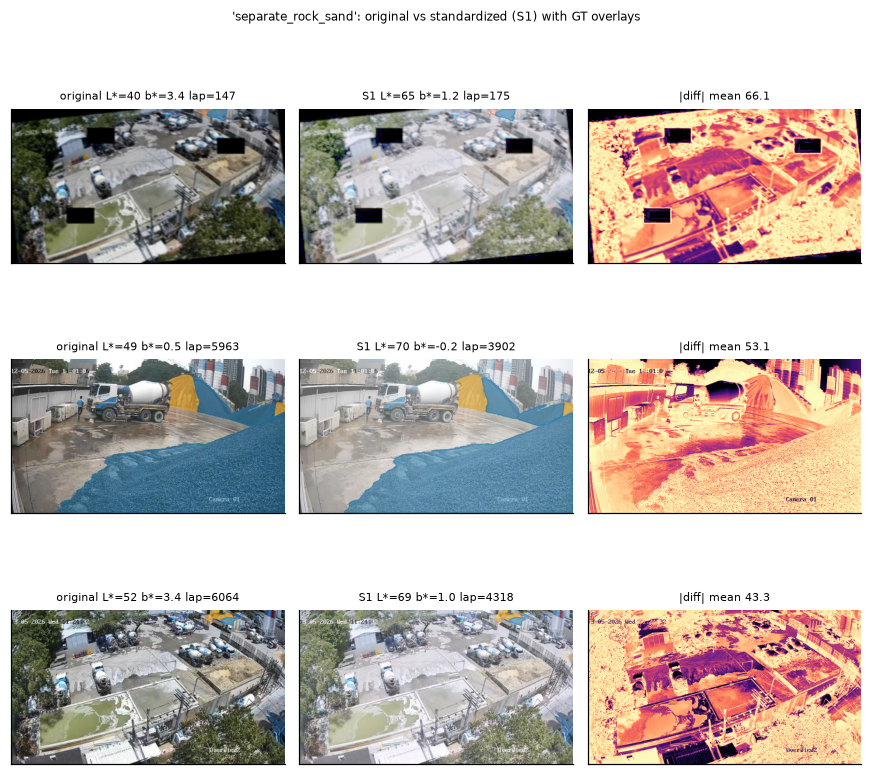

saved figure: outputs/04_holdout/figures/fig03_standardization_s02.png|pdf


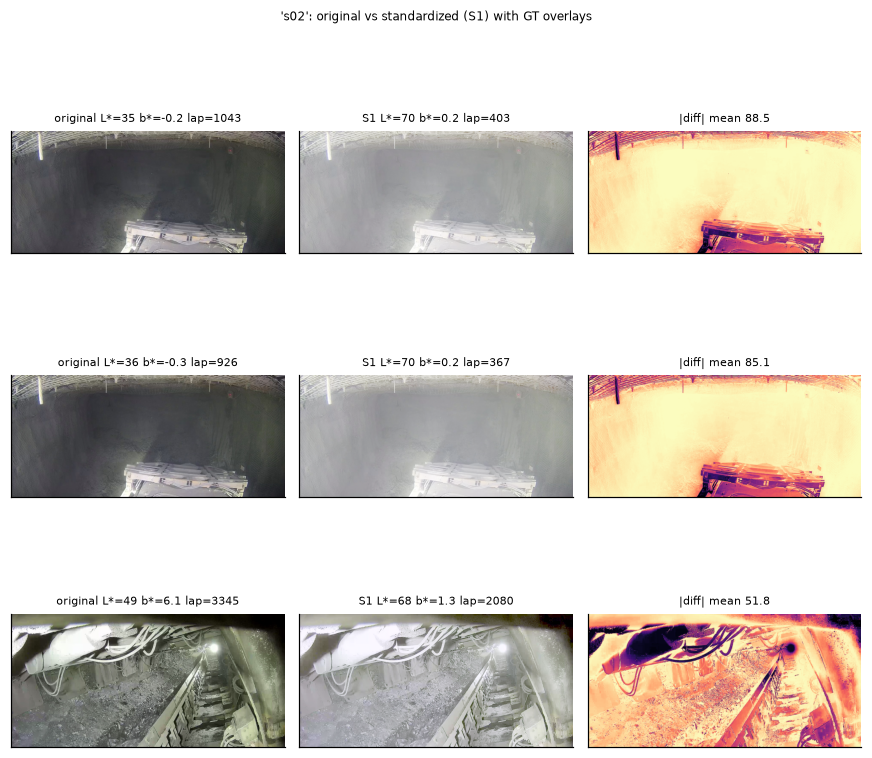

In [14]:
# ภาพตัวอย่างที่เลือกด้วยวิธีที่กำหนด: แต่ละชุด เลือกภาพที่ L* ใกล้เปอร์เซ็นไทล์ 10, 50, 90 ของชุดนั้น
SAMPLE_HO = []
for d in HO.dataset.unique():
    sub = HO[HO.dataset == d]
    for q in (10, 50, 90):
        t = np.percentile(sub.L_mean, q); SAMPLE_HO.append(sub.iloc[(sub.L_mean - t).abs().argmin()].image_id)
for d in HO.dataset.unique():
    ids = [i for i in SAMPLE_HO if HO.loc[HO.image_id == i, "dataset"].iloc[0] == d]
    fig, axes = plt.subplots(len(ids), 3, figsize=(8, 2.6 * len(ids)))
    for k, iid in enumerate(ids):
        r = HO[HO.image_id == iid].iloc[0]; img = cv2.imread(r.path); out = standardize_S1(img)
        sa, sb = image_stats(r.path), None
        tmp = OUT_ROOT / "tmp_std.jpg"; cv2.imwrite(str(tmp), out); sb = image_stats(str(tmp))
        draw_gt(axes[k, 0], iid, img); axes[k, 0].set_title(f"original L*={sa['L_mean']:.0f} b*={sa['b_mean']:.1f} lap={sa['lap_var']:.0f}", fontsize=7)
        draw_gt(axes[k, 1], iid, out); axes[k, 1].set_title(f"S1 L*={sb['L_mean']:.0f} b*={sb['b_mean']:.1f} lap={sb['lap_var']:.0f}", fontsize=7)
        dd = cv2.absdiff(out, img).mean(2); axes[k, 2].imshow(dd, cmap="magma"); axes[k, 2].set_title(f"|diff| mean {dd.mean():.1f}", fontsize=7)
        axes[k, 2].set_xticks([]); axes[k, 2].set_yticks([]); axes[k, 2].grid(False)
    fig.suptitle(f"'{d}': original vs standardized (S1) with GT overlays", fontsize=8); fig.tight_layout(); savefig(fig, FIG / f"fig03_standardization_{d}"); plt.show()

## 7. ผลบนชุด holdout

ส่วนนี้ตอบคำถามเดียวว่า **แบบจำลองที่ตรึงไว้ใช้ได้กับภาพจากแหล่งอื่นหรือไม่** โดยแบ่งเป็นคำถามย่อยตามลำดับ แต่ละหัวข้อแสดงรูปหลักหนึ่งรูปและตารางสรุปหนึ่งตาราง ตารางฉบับเต็มบันทึกไว้ใน `outputs/04_holdout/tables/`

| หัวข้อ | คำถาม | ตัวชี้วัดหลัก |
|---|---|---|
| 7.1 | ผลลดลงจากชุด test เท่าใด | mask AP50-95 (macro) และ F1 ของการตรวจพบวัสดุรายภาพ |
| 7.2 | ระบบตัดสินสถานะของภาพได้ถูกต้องเพียงใด | precision / recall / F1 ของการตรวจพบ gravel และ sand ในภาพ |
| 7.3 | ความผิดพลาดเกิดจากอะไร | สัดส่วนของ GT ที่ถูกทายถูกคลาส ผิดคลาส หรือไม่พบ; AP ตามขนาด; ผลตามการตรวจคุณภาพภาพ |
| 7.4 | การทำภาพให้เป็นมาตรฐาน (S1) ช่วยหรือไม่ | ผลต่างแบบคู่ S1 − S0 พร้อมช่วงความเชื่อมั่น 95% |
| 7.5 | แบบจำลองมั่นใจผิดที่ใด | ภาพผลการทำนายที่ confidence ≥ 0.8 และความไวต่อ threshold |
| 7.6 | ชุด S02 ที่ไม่มี label มีพฤติกรรมอย่างไร | การกระจายของ confidence เทียบกับชุด test |

**นิยามของเงื่อนไขภาพ** การประเมินทุกชุดทำบนภาพสองแบบที่ป้อนเข้าแบบจำลองหลังผ่าน preprocessing ที่ตรึงไว้ (`P5_unsharp`) เหมือนกัน

| รหัส | ความหมาย | การใช้ในรายงาน |
|---|---|---|
| **S0** (`S0_raw`) | ภาพดิบจากชุด holdout ไม่ปรับใด ๆ | เงื่อนไขหลักของหัวข้อ 7.1–7.3, 7.5 และ 7.6 |
| **S1** (`S1_dev_stats`) | ปรับสีด้วย gray-world แล้วปรับความสว่างด้วย gamma ให้ L\* เฉลี่ยเท่ากับค่ามัธยฐานของชุด train (หัวข้อ 6.2) | ใช้เฉพาะการทดสอบสมมติฐานในหัวข้อ 7.4 |

**Protocol** ใช้แบบจำลอง preprocessing และ threshold ที่ตรึงใน `configs/frozen_inference.yaml` ตรวจ SHA-256 ของ checkpoint ก่อนประเมิน ช่วงความเชื่อมั่น 95% ใช้ cluster bootstrap 1,000 รอบ โดยหน่วยคือ cluster ภาพเกือบซ้ำจากหัวข้อ 3 metric ระดับ instance ของทุกชุดใช้ protocol scope (GT ที่เล็กกว่า 32² px ในภาพ letterbox 640 เป็น ignore region; Notebook 03.5 หัวข้อ 3.0) ค่าอ้างอิงระดับ instance ของชุด test คำนวณใหม่จาก detection ที่ Notebook 03 บันทึกไว้ภายใต้ protocol เดียวกัน ส่วนค่าอ้างอิงระดับสถานะมาจาก `test_summary.json` ซึ่งมีเพียง 7 cluster ช่วงความเชื่อมั่นของ test จึงกว้าง

**การเปิดผล** holdout ถูกเปิดครั้งแรกในรอบที่หนึ่ง (ผลอยู่ใน `outputs/_archive_round1/04_holdout/`) การประเมินในรอบนี้ใช้แบบจำลองที่ตรึงใหม่หลังแก้ bug และเปลี่ยนนโยบายการฝึก จึงเป็นการวิเคราะห์หลังเปิดผล เมื่อมีไฟล์ `HOLDOUT_OPENED.json` แล้ว การรันซ้ำจะคำนวณ metric จาก detection ที่บันทึกไว้ใน `outputs/04_holdout/dets/` เท่านั้น ไม่รันแบบจำลองบน holdout ใหม่

In [15]:
assert FROZEN_PATH.exists(), "G5: ต้องตรึงการตั้งค่าใน Notebook 03 ก่อน"
FROZEN = _yaml.safe_load(FROZEN_PATH.read_text())
W = ROOT / FROZEN["weights"]; assert sha256_file(W) == FROZEN["weights_sha256"], "checkpoint does not match frozen config"
if FROZEN.get("attention") and FROZEN["attention"]["kind"] in ("cbam", "eca"):
    # CBAM/ECA เป็นโมดูลที่เขียนขึ้นเองและต้องนิยามคลาสก่อนโหลด; C3k2 attn=True เป็นโมดูลมาตรฐานของ Ultralytics จึงโหลดได้โดยตรง
    ATT_SPEC.update(kind=FROZEN["attention"]["kind"], layers=FROZEN["attention"]["layers"])
PP_FROZEN = FROZEN.get("preprocessing")
assert PP_FROZEN in (None, "P1_grayworld", "P2_clahe", "P3_gamma_auto", "P4_nlmeans", "P5_unsharp"), "re-implement the frozen preprocessing identically before evaluating"
def _clahe(img, clip=2.0, grid=8):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); l, a, b = cv2.split(lab)
    return cv2.cvtColor(cv2.merge([cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(l), a, b]), cv2.COLOR_LAB2BGR)
def _denoise(img, h=3):
    return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)
def _unsharp(img, sigma=1.0, amount=0.5):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)
P3_TARGET_L = (FROZEN.get("preprocessing_params") or {}).get("TARGET_L")   # ค่าจาก train ของชุดพัฒนา (ต่างจาก TARGET_L ของ standardization)
def _gamma_auto_frozen(img, target=P3_TARGET_L):
    L = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[..., 0].mean() / 255
    g = np.log(target / 100) / np.log(max(min(L, 0.99), 0.01))
    return cv2.LUT(img, ((np.arange(256) / 255.0) ** g * 255).clip(0, 255).astype(np.uint8))
PP_FN = {None: None, "P1_grayworld": std_grayworld, "P2_clahe": _clahe, "P3_gamma_auto": _gamma_auto_frozen if P3_TARGET_L else None,
         "P4_nlmeans": _denoise, "P5_unsharp": _unsharp}[PP_FROZEN]
assert PP_FROZEN is None or PP_FN is not None, "preprocessing parameters missing from frozen config"
IMGSZ_F = int(FROZEN.get("imgsz", 640))
def pipeline(std_fn):
    # standardization ทำก่อน preprocessing ที่ตรึงไว้ของแบบจำลอง
    fs = [f for f in (std_fn, PP_FN) if f is not None]
    if not fs:
        return None
    def run(img):
        for f in fs:
            img = f(img)
        return img
    return run
HO_FLAG = OUT_ROOT / "HOLDOUT_OPENED.json"
print(json.dumps({k: FROZEN[k] for k in ("selected", "weights", "weights_sha256", "preprocessing", "conf_thresholds", "state_thresholds")}, indent=2))

{
  "selected": "R2_yolo26s__C1_cbam_P3",
  "weights": "outputs/03_yolo_experiments/architecture_ablations/R2_yolo26s__C1_cbam_P3_s42_c8de8872/weights/best.pt",
  "weights_sha256": "accdf2e4453c5c3cbeaa3b39d76898c34a491d6a109b82c6d4cc33458234e09a",
  "preprocessing": "P5_unsharp",
  "conf_thresholds": {
    "gravel": 0.37,
    "sand": 0.28
  },
  "state_thresholds": {
    "gravel": 0.014245966302328453,
    "sand": 0.001276440419015716
  }
}


### 7.0 การคำนวณผล

เซลล์ต่อไปนี้คำนวณ metric ทุกตัวที่กำหนดไว้ล่วงหน้าและบันทึกเป็นตาราง ได้แก่ L1 (`holdout_results.csv`), ผลต่างแบบคู่ S1 − S0 (`standardization_paired_difference.csv`), L2 ระดับภาพ (`image_level_*.csv`) และสรุปของ S02 (`s02_prediction_summary.csv`) โดยยังไม่แสดงผล ผลแต่ละส่วนแสดงในหัวข้อย่อยที่ตอบคำถามนั้น

In [16]:
EVAL = {}
if RUN_HOLDOUT_EVAL:
    REUSE_DETS = HO_FLAG.exists()
    if REUSE_DETS:
        # holdout ถูกเปิดแล้ว: ใช้ detection ที่บันทึกไว้จากการเปิดครั้งนั้นเท่านั้น และตรวจว่าเป็น checkpoint เดียวกัน
        opened = json.loads(HO_FLAG.read_text()); assert opened["weights_sha256"] == FROZEN["weights_sha256"], "checkpoint differs from the opened run"
        missing = [f"{d}_{s}" for d in GT_HO for s in STANDARD if not (OUT_ROOT / "dets" / f"{d}_{s}.json.gz").exists()]
        assert not missing, f"refusing to re-open the holdout: cached detections missing for {missing}"
        print("holdout opened", opened["opened"], "-> recomputing metrics from cached detections (no new inference)")
    else:
        HO_FLAG.write_text(json.dumps(dict(opened=time.strftime("%Y-%m-%dT%H:%M:%S%z"), weights_sha256=FROZEN["weights_sha256"]), indent=2))
    rows = []
    for d, gt in GT_HO.items():
        R = HO[(HO.dataset == d) & HO.label_path.notna()].copy().rename(columns={"cluster": "group_merged"})
        for sname, sfn in STANDARD.items():
            dets = cached_dets(OUT_ROOT / "dets" / f"{d}_{sname}.json.gz", lambda R=R, sfn=sfn: predict_dets(W, R, imgsz=IMGSZ_F, transform=pipeline(sfn), desc=f"{d} {sname}"))
            res = l1_evaluate(gt, dets, R); res_i = l1_evaluate(gt, dets, R, "ignore"); res_s = l1_evaluate(gt, dets, R, "strict")
            sc = state_scores(dets, R); l2, l2df = l2_evaluate(sc, R, FROZEN["state_thresholds"])
            ops = {c: operating_point(res["segm"]["recs"], R.image_id.tolist(), i + 1, thresholds=[FROZEN["conf_thresholds"][c]]).iloc[0].to_dict()
                   for i, c in enumerate(CLASS_NAMES)}
            boot = bootstrap_mask_ap(res, R, 1000)
            qc_ids = R.image_id[R.qc_pass].tolist(); nq_ids = R.image_id[~R.qc_pass].tolist()
            EVAL[(d, sname)] = dict(res=res, res_ignore=res_i, res_strict=res_s, dets=dets, R=R, l2df=l2df, boot=boot, ops=ops)
            rows.append(dict(dataset=d, standardization=sname, n=len(R), **summarize_l1(res), **summarize_l1(res_i, "ignore_"), **summarize_l1(res_s, "strict_"),
                             l2_macro_f1=l2["macro_f1"], l2_bal_acc=l2["balanced_accuracy"], presence_AP_gravel=l2["presence_AP_gravel"],
                             presence_AP_sand=l2["presence_AP_sand"], mask_AP_macro_ci_low=boot["ci_low"], mask_AP_macro_ci_high=boot["ci_high"],
                             mask_AP_qc_pass=np.nanmean([ap_from_records(res["segm"]["recs"], qc_ids, c) for c in (1, 2)]) if qc_ids else np.nan,
                             mask_AP_qc_fail=np.nanmean([ap_from_records(res["segm"]["recs"], nq_ids, c) for c in (1, 2)]) if nq_ids else np.nan,
                             **{f"op_{c}_{k}": v for c, o in ops.items() for k, v in o.items() if k in ("precision", "recall", "F1", "TP", "FP", "FN")}))
            l2df.to_csv(OUT_ROOT / f"state_predictions_{d}_{sname}.csv", index=False)
    HOLD = pd.DataFrame(rows); save_table(HOLD, TAB / "holdout_results.csv")

print("computed:", list(EVAL))

holdout opened 2026-10-19T00:33:24+0700 -> recomputing metrics from cached detections (no new inference)


saved table: outputs/04_holdout/tables/holdout_results.csv (4 rows)
computed: [('piled_materials', 'S0_raw'), ('piled_materials', 'S1_dev_stats'), ('separate_rock_sand', 'S0_raw'), ('separate_rock_sand', 'S1_dev_stats')]


In [17]:
# ผลต่างแบบคู่ S1 − S0 ด้วย cluster bootstrap (ภาพชุดเดียวกัน)
if EVAL:
    diff_rows = []
    for d in GT_HO:
        r0, r1 = EVAL[(d, "S0_raw")], EVAL[(d, "S1_dev_stats")]; R = r0["R"]
        def stat(ids):
            a0 = np.nanmean([ap_from_records(r0["res"]["segm"]["recs"], ids, c) for c in (1, 2)])
            a1 = np.nanmean([ap_from_records(r1["res"]["segm"]["recs"], ids, c) for c in (1, 2)])
            return a1 - a0
        b = cluster_bootstrap(R, stat, 1000)
        diff_rows.append(dict(dataset=d, delta_macro_mask_AP=stat(R.image_id.tolist()), ci_low=b["ci_low"], ci_high=b["ci_high"], n_clusters=b["n_clusters"]))
    DIFF = pd.DataFrame(diff_rows); save_table(DIFF, TAB / "standardization_paired_difference.csv")

saved table: outputs/04_holdout/tables/standardization_paired_difference.csv (2 rows)


In [18]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, cohen_kappa_score, precision_recall_fscore_support, confusion_matrix

def presence_metrics(y, p):
    tp = int((y & p).sum()); fp = int((~y & p).sum()); fn = int((y & ~p).sum()); tn = int((~y & ~p).sum())
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, accuracy=(tp + tn) / max(tp + fp + fn + tn, 1), precision=tp / max(tp + fp, 1),
                recall=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1), F1=2 * tp / max(2 * tp + fp + fn, 1))

def image_level_report(df, d, sname, n_boot=1000):
    y, p = df.state.values, df.pred_state.values
    labels = [s for s in STATES if s in set(y) | set(p)]
    pr, rc, f1, sup = precision_recall_fscore_support(y, p, labels=labels, zero_division=0)
    per_state = pd.DataFrame(dict(dataset=d, standardization=sname, state=labels, precision=pr, recall=rc, F1=f1, support=sup))
    overall = dict(dataset=d, standardization=sname, n=len(df), accuracy=accuracy_score(y, p), balanced_accuracy=balanced_accuracy_score(y, p),
                   macro_F1=f1_score(y, p, labels=labels, average="macro", zero_division=0), kappa=cohen_kappa_score(y, p))
    pres = []
    for c in CLASS_NAMES:
        yc = np.isin(y, [c, "mixed"]); pc = np.isin(p, [c, "mixed"])
        pres.append(dict(dataset=d, standardization=sname, material=c, **presence_metrics(yc, pc)))
    # cluster bootstrap (หน่วยคือ cluster ของภาพเกือบซ้ำ)
    rng = np.random.default_rng(SEED); groups = df.group_merged.unique()
    by_g = {g: np.flatnonzero(df.group_merged.values == g) for g in groups}
    boot = defaultdict(list)
    for _ in range(n_boot):
        ii = np.concatenate([by_g[g] for g in rng.choice(groups, size=len(groups), replace=True)])
        yb, pb = y[ii], p[ii]
        boot["accuracy"].append(accuracy_score(yb, pb)); boot["macro_F1"].append(f1_score(yb, pb, labels=labels, average="macro", zero_division=0))
        for c in CLASS_NAMES:
            boot[f"F1_{c}"].append(presence_metrics(np.isin(yb, [c, "mixed"]), np.isin(pb, [c, "mixed"]))["F1"])
    for k in ("accuracy", "macro_F1"):
        overall[f"{k}_ci_low"], overall[f"{k}_ci_high"] = np.percentile(boot[k], [2.5, 97.5])
    for r in pres:
        r["F1_ci_low"], r["F1_ci_high"] = np.percentile(boot[f"F1_{r['material']}"], [2.5, 97.5])
    overall["n_clusters"] = len(groups)
    return overall, per_state, pres, confusion_matrix(y, p, labels=labels), labels

if EVAL:
    OV, PS, PR_, CMS = [], [], [], {}
    for (d, sname) in EVAL:
        df = pd.read_csv(OUT_ROOT / f"state_predictions_{d}_{sname}.csv")
        o, ps, pr, cm, labels = image_level_report(df, d, sname)
        OV.append(o); PS.append(ps); PR_ += pr; CMS[(d, sname)] = (cm, labels)
    OV = pd.DataFrame(OV); PS = pd.concat(PS); PR_ = pd.DataFrame(PR_)
    save_table(OV, TAB / "image_level_overall.csv"); save_table(PS, TAB / "image_level_per_state.csv"); save_table(PR_, TAB / "image_level_presence.csv")
else:
    print("holdout not evaluated (RUN_HOLDOUT_EVAL = False)")

saved table: outputs/04_holdout/tables/image_level_overall.csv (4 rows)
saved table: outputs/04_holdout/tables/image_level_per_state.csv (16 rows)
saved table: outputs/04_holdout/tables/image_level_presence.csv (8 rows)


In [19]:
# S02 (ไม่มี label): สถานะที่ทำนายและการกระจายของ confidence
if RUN_HOLDOUT_EVAL:
    R = HO[HO.dataset == "s02"].copy()
    s02_rows = []
    for sname, sfn in STANDARD.items():
        dets = cached_dets(OUT_ROOT / "dets" / f"s02_{sname}.json.gz", lambda sfn=sfn: predict_dets(W, R, imgsz=IMGSZ_F, transform=pipeline(sfn), desc=f"s02 {sname}"))
        sc = state_scores(dets, R)
        st = states_from_presence(sc.S_gravel.values >= FROZEN["state_thresholds"]["gravel"], sc.S_sand.values >= FROZEN["state_thresholds"]["sand"])
        confs = [x["score"] for x in dets if x["score"] >= 0.05]
        s02_rows.append(dict(standardization=sname, n=len(R), **{f"frac_{s}": float((st == s).mean()) for s in STATES},
                             median_conf=float(np.median(confs)) if confs else np.nan, dets_per_image=len(confs) / len(R)))
    S02 = pd.DataFrame(s02_rows); save_table(S02, TAB / "s02_prediction_summary.csv")

saved table: outputs/04_holdout/tables/s02_prediction_summary.csv (2 rows)


In [20]:
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
VIS_CONF = 0.8   # post-hoc เพื่อการแสดงผลเท่านั้น (ไม่แทน threshold ที่ตรึงไว้)
CLS_RGB = {c: np.asarray(matplotlib.colors.to_rgb(CLASS_COLORS[c])) for c in CLASS_NAMES}
CLS_TXT = {"gravel": (1.0, 1.0, 1.0), "sand": (0.04, 0.04, 0.04)}   # สีตัวอักษรบนป้ายที่อ่านได้บนสีของคลาส

def load_dets(d, sname):
    if (d, sname) in EVAL:
        return EVAL[(d, sname)]["dets"]
    with gzip.open(OUT_ROOT / "dets" / f"{d}_{sname}.json.gz", "rt") as f:
        return json.load(f)

def draw_pred(img_bgr, dets_img, conf=VIS_CONF, gt_iid=None):
    """คืนภาพ RGB ที่วาด mask, bbox และป้ายชื่อคลาสของ detection ที่ conf >= ค่าที่กำหนด (ป้ายไม่แสดงค่า confidence)"""
    im = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255
    H, W = im.shape[:2]; s = max(W, H) / 640
    lw, fs = max(2, round(2.2 * s)), 0.85 * s
    keep = sorted([d for d in dets_img if d["score"] >= conf], key=lambda d: d["score"])
    masks = [(d, mask_util.decode(d["segmentation"]) > 0) for d in keep]
    for d, m in masks:
        im[m] = 0.62 * im[m] + 0.38 * CLS_RGB[CLASS_NAMES[d["category_id"] - 1]]
    out = (im * 255).astype(np.uint8).copy()
    if gt_iid is not None:
        for g in HS[(HS.image_id == gt_iid) & (HS.role == "normal")].itertuples():
            cv2.polylines(out, [np.asarray(g.geom.exterior.coords, np.int32)], True, (255, 255, 255), max(1, lw - 1), cv2.LINE_AA)
    for d, m in masks:
        c = CLASS_NAMES[d["category_id"] - 1]; col = tuple(int(255 * v) for v in CLS_RGB[c])
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cs, -1, col, lw, cv2.LINE_AA)
        x, y, w, h = map(int, d["bbox"]); cv2.rectangle(out, (x, y), (x + w, y + h), col, max(1, lw - 1))
        lab = c; (tw, th), bl = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, fs, lw)
        ty = y if y - th - bl - 2 >= 0 else y + th + bl + 2
        cv2.rectangle(out, (x, ty - th - bl - 2), (x + tw + 4, ty), col, -1)
        cv2.putText(out, lab, (x + 2, ty - bl), cv2.FONT_HERSHEY_SIMPLEX, fs, tuple(int(255 * v) for v in CLS_TXT[c]), lw, cv2.LINE_AA)
    return out, len(keep)

def pick_images(d, per_state=3, n=12):
    sub = HO[HO.dataset == d]
    if d not in GT_HO:
        return sub.sample(min(n, len(sub)), random_state=SEED).image_id.tolist()
    ids = []
    for st in STATES:
        s_ = sub[sub.state == st].sample(frac=1, random_state=SEED).drop_duplicates("cluster")
        ids += s_.head(per_state).image_id.tolist()
    return ids[:n]


DS_LABEL = {"test": "dev test (ref.)", "piled_materials": "Piled Materials", "separate_rock_sand": "Separate Rock-Sand", "s02": "S02 (unlabelled)"}
OUTCOME = {"correct": "#2a9d4b", "wrong class": "#8e5bd0", "missed": "#b8b6ae", "background": "#b8b6ae"}   # ผ่าน validator ของ dataviz
INK, INK2 = "#0b0b0b", "#52514e"
LABELLED = list(GT_HO)

# ค่าอ้างอิงจากชุด test ของชุดพัฒนา (Notebook 03): สรุปและ detection ที่บันทึกไว้ (ไม่โหลดภาพ test)
EVAL_DIR = ROOT / "outputs" / "03_yolo_experiments" / "evaluation"
TEST_SUM = json.loads((EVAL_DIR / "test_summary.json").read_text())
with gzip.open(EVAL_DIR / "dets_test.json.gz", "rt") as f:
    DETS_TEST = json.load(f)
GT_TEST = DEV_DIR / "annotations" / "test_coco.json"
TEST_IDS = [im["id"] for im in json.loads(GT_TEST.read_text())["images"]]
# metric ระดับ instance ของ test คำนวณใหม่จาก detection ของ Notebook 03 ภายใต้ protocol เดียวกับ holdout (scope); metric ระดับสถานะใช้ test_summary.json
TEST_R = MANIFEST[MANIFEST.split == "test"][["image_id", "width", "height", "group_merged"]].reset_index(drop=True)
RES_TEST = l1_evaluate(GT_TEST, DETS_TEST, TEST_R); BOOT_TEST = bootstrap_mask_ap(RES_TEST, TEST_R, 1000)
OP_TEST = {c: operating_point(RES_TEST["segm"]["recs"], TEST_IDS, i + 1, thresholds=[FROZEN["conf_thresholds"][c]]).iloc[0].to_dict()
           for i, c in enumerate(CLASS_NAMES)}

def presence_from_confusion(l2):
    # F1 ของการตรวจพบวัสดุจาก confusion matrix สี่สถานะ (mixed นับเป็นบวกของทั้งสองวัสดุ)
    cm, lab = np.asarray(l2["confusion"]), l2["labels"]; out = {}
    for c in CLASS_NAMES:
        pos = np.array([l in (c, "mixed") for l in lab])
        tp = cm[np.ix_(pos, pos)].sum(); fp = cm[np.ix_(~pos, pos)].sum(); fn = cm[np.ix_(pos, ~pos)].sum()
        out[c] = 2 * tp / max(2 * tp + fp + fn, 1)
    return out

def clean_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)

### 7.1 ผลลดลงจากชุด test เท่าใด

**Method** เปรียบเทียบชุด test ของชุดพัฒนากับชุด holdout ที่มี label สองชุด บนภาพ S0 ในสองระดับ ได้แก่ระดับ instance (mask AP50-95 เฉลี่ยสองคลาส และ AP ของแต่ละคลาส) และระดับภาพ (F1 ของการตรวจพบ gravel และ sand ซึ่งเป็นผลลัพธ์ที่ระบบใช้งานจริง) เส้นแนวนอนคือช่วงความเชื่อมั่น 95%

**การอ่านผล** ระยะห่างระหว่างจุดของ test กับ holdout คือขนาดของการลดลงเมื่อเปลี่ยนแหล่งภาพ ค่าของ test มีช่วงความเชื่อมั่นกว้างเพราะมีเพียง 7 cluster

saved table: outputs/04_holdout/tables/holdout_headline.csv (3 rows)


,images,clusters,mask_AP,AP_ci_low,AP_ci_high,mask_AP50,AP_gravel,AP_sand,F1_gravel,F1_sand
dataset,,,,,,,,,,
dev test (ref.),244,7,0.534,0.414,0.772,0.806,0.638,0.430,1.000,1.000
Piled Materials,1095,1031,0.075,0.065,0.093,0.156,0.071,0.080,0.541,0.737
Separate Rock-Sand,182,96,0.087,0.044,0.148,0.109,0.052,0.121,0.423,0.636


saved figure: outputs/04_holdout/figures/fig10_headline_test_vs_holdout.png|pdf


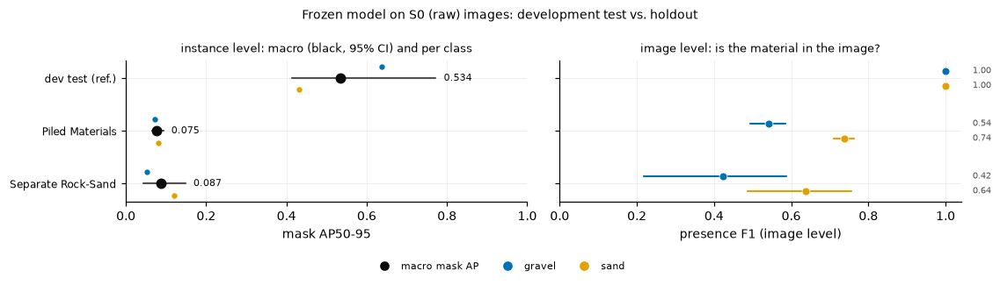

In [21]:
pt = summarize_l1(RES_TEST); tb = BOOT_TEST; tf1 = presence_from_confusion(TEST_SUM["l2"])
rows = [dict(dataset="test", images=TEST_SUM["l2"]["n"], clusters=tb["n_clusters"], mask_AP=pt["mask_AP"], AP_ci_low=tb["ci_low"], AP_ci_high=tb["ci_high"],
             mask_AP50=pt["mask_AP50"], AP_gravel=pt["mask_AP_gravel"], AP_sand=pt["mask_AP_sand"],
             F1_gravel=tf1["gravel"], F1_gravel_lo=np.nan, F1_gravel_hi=np.nan, F1_sand=tf1["sand"], F1_sand_lo=np.nan, F1_sand_hi=np.nan)]
for d in LABELLED:
    e = EVAL[(d, "S0_raw")]; st = e["res"]["segm"]["stats"]; pc = e["res"]["segm"]["per_class"]
    p = PR_[(PR_.dataset == d) & (PR_.standardization == "S0_raw")].set_index("material")
    rows.append(dict(dataset=d, images=len(e["R"]), clusters=e["boot"]["n_clusters"], mask_AP=st["AP"], AP_ci_low=e["boot"]["ci_low"],
                     AP_ci_high=e["boot"]["ci_high"], mask_AP50=st["AP50"], AP_gravel=pc["gravel"]["AP"], AP_sand=pc["sand"]["AP"],
                     **{f"F1_{c}{s}": p.loc[c, k] for c in CLASS_NAMES for s, k in (("", "F1"), ("_lo", "F1_ci_low"), ("_hi", "F1_ci_high"))}))
HEAD = pd.DataFrame(rows); save_table(HEAD, TAB / "holdout_headline.csv")
display(HEAD[["dataset", "images", "clusters", "mask_AP", "AP_ci_low", "AP_ci_high", "mask_AP50", "AP_gravel", "AP_sand", "F1_gravel", "F1_sand"]]
        .assign(dataset=HEAD.dataset.map(DS_LABEL)).set_index("dataset").round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.4, 2.7), sharey=True)
y = np.arange(len(HEAD))[::-1]
ax = axes[0]
for yi, r in zip(y, HEAD.itertuples()):
    ax.plot([r.AP_ci_low, r.AP_ci_high], [yi, yi], color=INK2, lw=1.4, solid_capstyle="round")
    ax.scatter(r.mask_AP, yi, s=46, color=INK, zorder=3)
    ax.text(r.AP_ci_high + 0.02, yi, f"{r.mask_AP:.3f}", va="center", fontsize=7, color=INK)
    for c, dy in (("gravel", 0.22), ("sand", -0.22)):
        v = getattr(r, f"AP_{c}"); ax.scatter(v, yi + dy, s=22, color=CLASS_COLORS[c], zorder=3, edgecolors="white", linewidths=0.5)
ax.set_xlim(0, 1); ax.set_yticks(y); ax.set_yticklabels(HEAD.dataset.map(DS_LABEL), fontsize=8)
ax.set_xlabel("mask AP50-95"); ax.set_title("instance level: macro (black, 95% CI) and per class", fontsize=8.5)
ax = axes[1]
for yi, r in zip(y, HEAD.itertuples()):
    for c, dy in (("gravel", 0.14), ("sand", -0.14)):
        v, lo, hi = getattr(r, f"F1_{c}"), getattr(r, f"F1_{c}_lo"), getattr(r, f"F1_{c}_hi")
        if not np.isnan(lo):
            ax.plot([lo, hi], [yi + dy] * 2, color=CLASS_COLORS[c], lw=1.4, solid_capstyle="round")
        ax.scatter(v, yi + dy, s=34, color=CLASS_COLORS[c], zorder=3, edgecolors="white", linewidths=0.5)
        ax.text(1.07, yi + dy, f"{v:.2f}", va="center", fontsize=6.5, color=INK2, clip_on=False)
ax.set_xlim(0, 1.04); ax.set_xlabel("presence F1 (image level)"); ax.set_title("image level: is the material in the image?", fontsize=8.5)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=INK, label="macro mask AP"),
                    Line2D([], [], marker="o", ls="", color=CLASS_COLORS["gravel"], label="gravel"),
                    Line2D([], [], marker="o", ls="", color=CLASS_COLORS["sand"], label="sand")],
           loc="lower center", ncol=3, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Frozen model on S0 (raw) images: development test vs. holdout", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1)); savefig(fig, FIG / "fig10_headline_test_vs_holdout"); plt.show()

### 7.2 ระบบตัดสินสถานะของภาพได้ถูกต้องเพียงใด

**Method** ระบบใช้คะแนน $S_c$ ของภาพกับเกณฑ์ $\theta_c$ ที่ตรึงไว้ เพื่อตัดสินว่าภาพมี gravel และ/หรือ sand หรือไม่ ตารางแสดง TP, FP, FN, TN, precision, recall และ F1 ของการตรวจพบรายวัสดุ (S0) ส่วนรูปแสดง confusion matrix สี่สถานะ โดยตัวเลขในช่องคือจำนวนภาพและสัดส่วนต่อแถว

**ข้อควรระวัง** ภาพของ Separate Rock-Sand เกือบทั้งหมดมีสถานะ `mixed` (ภาพมุมกว้างของลานกองวัสดุ) accuracy สี่สถานะของชุดนี้จึงสะท้อนเพียงคลาสเดียว การอ่านผลของชุดนี้ควรใช้การตรวจพบรายวัสดุในตาราง

TP   FP   FN   TN  precision  recall     F1  \
dataset            material                                                 
Piled Materials    gravel    206   76  273  540      0.730   0.430  0.541   
                   sand      564  342   61  128      0.623   0.902  0.737   
Separate Rock-Sand gravel     48    0  131    3      1.000   0.268  0.423   
                   sand       84    3   93    2      0.966   0.475  0.636   

                             F1_ci_low  F1_ci_high  
dataset            material                         
Piled Materials    gravel        0.494       0.586  
                   sand          0.711       0.764  
Separate Rock-Sand gravel        0.217       0.587  
                   sand          0.488       0.755

saved figure: outputs/04_holdout/figures/image_level_confusion.png|pdf


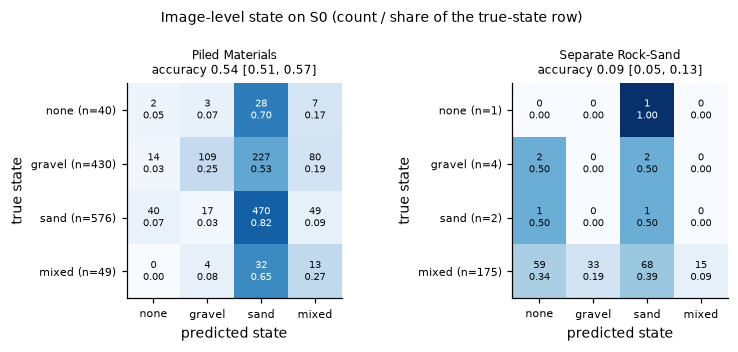

In [22]:
pres = PR_[PR_.standardization == "S0_raw"].assign(dataset=lambda x: x.dataset.map(DS_LABEL))
display(pres[["dataset", "material", "TP", "FP", "FN", "TN", "precision", "recall", "F1", "F1_ci_low", "F1_ci_high"]].set_index(["dataset", "material"]).round(3))
fig, axes = plt.subplots(1, len(LABELLED), figsize=(3.6 * len(LABELLED), 3.2))
for ax, d in zip(np.atleast_1d(axes), LABELLED):
    cm, labels = CMS[(d, "S0_raw")]; rs = cm.sum(1, keepdims=True); cmn = np.divide(cm, rs, out=np.zeros(cm.shape), where=rs > 0)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if cmn[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, fontsize=7); ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([f"{l} (n={n})" for l, n in zip(labels, cm.sum(1))], fontsize=7)
    o = OV[(OV.dataset == d) & (OV.standardization == "S0_raw")].iloc[0]
    ax.set_title(f"{DS_LABEL[d]}\naccuracy {o.accuracy:.2f} [{o.accuracy_ci_low:.2f}, {o.accuracy_ci_high:.2f}]", fontsize=8)
    ax.set_xlabel("predicted state"); ax.set_ylabel("true state"); ax.grid(False)
fig.suptitle("Image-level state on S0 (count / share of the true-state row)", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "image_level_confusion"); plt.show()

### 7.3 ความผิดพลาดเกิดจากอะไร

**Method** วิเคราะห์สามมุมบนภาพ S0 ที่ threshold ที่ตรึงไว้ โดยเทียบกับชุด test

1. **ปลายทางของ GT แต่ละชิ้น:** จับคู่ detection กับ GT โดยไม่สนใจคลาส (mask IoU ≥ 0.5 เรียงตาม confidence) แล้วนับว่า GT ถูกทายเป็นคลาสที่ถูก คลาสอื่น หรือไม่พบ และในทางกลับกัน นับว่า detection แต่ละชิ้นตรงกับ GT คลาสเดียวกัน คลาสอื่น หรือพื้นหลัง detection ที่ทับ ignore region ไม่นับ
2. **ขนาดของวัตถุ:** mask AP ตามช่วงขนาดมาตรฐานของ COCO (small < 32², medium < 96², large ≥ 96² พิกเซล) ซึ่งใช้นิยามเดียวกันทุกชุด
3. **คุณภาพของภาพ:** mask AP ของภาพที่ผ่านและไม่ผ่านการตรวจคุณภาพในหัวข้อ 6.2

**Rationale** การลดลงของ AP อาจเกิดจากการตรวจไม่พบ การทายผิดคลาส หรือ false positive บนพื้นหลัง ซึ่งนำไปสู่การแก้ไขต่างกัน ได้แก่ การเพิ่มข้อมูลของโดเมนใหม่ การทบทวนการ map คลาส Rock → gravel หรือการปรับ threshold

saved table: outputs/04_holdout/tables/instance_outcomes.csv (30 rows)


saved figure: outputs/04_holdout/figures/fig11_error_anatomy.png|pdf


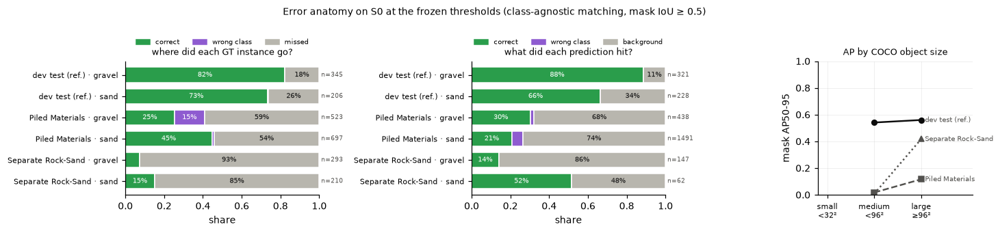

,mask_AP_qc_pass,mask_AP_qc_fail,n_pass,n_fail
dataset,,,,
Piled Materials,0.144,0.074,66,1029
Separate Rock-Sand,NaN,0.087,0,182


share of GT gravel predicted as sand: {'Piled Materials': 0.155}


In [23]:
def instance_outcomes(gt_json, dets, img_ids, iou_thr=0.5):
    """จับคู่แบบไม่สนใจคลาสที่ threshold ที่ตรึงไว้: คืน (ปลายทางของ GT, องค์ประกอบของ detection) ต่อคลาส"""
    gt = load_gt(gt_json); by = defaultdict(list)
    for x in dets:
        if x["score"] >= FROZEN["conf_thresholds"][CLASS_NAMES[x["category_id"] - 1]]:
            by[x["image_id"]].append(x)
    G_out, D_out = Counter(), Counter()
    for iid in map(int, img_ids):
        anns = gt.imgToAnns[iid]; G = [a for a in anns if not a.get("iscrowd", 0)]; IG = [a for a in anns if a.get("iscrowd", 0)]
        ds = sorted(by[iid], key=lambda x: -x["score"]); d_rle = [x["segmentation"] for x in ds]
        g_rle = [gt.annToRLE(a) for a in G]; ig_rle = [gt.annToRLE(a) for a in IG]
        iou = np.asarray(mask_util.iou(d_rle, g_rle, [0] * len(g_rle))).reshape(len(ds), len(G)) if ds and G else np.zeros((len(ds), len(G)))
        ioa = np.asarray(mask_util.iou(d_rle, ig_rle, [1] * len(ig_rle))).reshape(len(ds), len(IG)) if ds and IG else np.zeros((len(ds), 0))
        used = {}
        for q, x in enumerate(ds):
            pc = CLASS_NAMES[x["category_id"] - 1]
            cand = [(iou[q, j], j) for j in range(len(G)) if j not in used and iou[q, j] >= iou_thr]
            if cand:
                j = max(cand)[1]; gc = CLASS_NAMES[G[j]["category_id"] - 1]; used[j] = pc
                D_out[(pc, "correct" if gc == pc else "wrong class")] += 1
            elif ioa.shape[1] and ioa[q].max() >= 0.5:
                continue
            else:
                D_out[(pc, "background")] += 1
        for j, a in enumerate(G):
            gc = CLASS_NAMES[a["category_id"] - 1]
            G_out[(gc, "missed" if j not in used else "correct" if used[j] == gc else "wrong class")] += 1
    return G_out, D_out

SRC = {"test": (GT_TEST, DETS_TEST, TEST_IDS), **{d: (GT_HO[d], EVAL[(d, "S0_raw")]["dets"], EVAL[(d, "S0_raw")]["R"].image_id) for d in LABELLED}}
OUT_ROWS = []
for d, (g, dt, ii) in SRC.items():
    Go, Do = instance_outcomes(g, dt, ii)
    for (c, k), n in Go.items():
        OUT_ROWS.append(dict(dataset=d, side="GT", cls=c, outcome=k, n=n))
    for (c, k), n in Do.items():
        OUT_ROWS.append(dict(dataset=d, side="prediction", cls=c, outcome=k, n=n))
OUTC = pd.DataFrame(OUT_ROWS); OUTC["share"] = OUTC.n / OUTC.groupby(["dataset", "side", "cls"]).n.transform("sum")
save_table(OUTC, TAB / "instance_outcomes.csv")

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.1), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
for ax, side, order, title in ((axes[0], "GT", ["correct", "wrong class", "missed"], "where did each GT instance go?"),
                               (axes[1], "prediction", ["correct", "wrong class", "background"], "what did each prediction hit?")):
    keys = [(d, c) for d in SRC for c in CLASS_NAMES]; yy = np.arange(len(keys))[::-1]
    for yi, (d, c) in zip(yy, keys):
        sub = OUTC[(OUTC.dataset == d) & (OUTC.side == side) & (OUTC.cls == c)].set_index("outcome"); left = 0
        tot = int(sub.n.sum())
        for k in order:
            v = float(sub.share.get(k, 0.0))
            ax.barh(yi, v, left=left, height=0.72, color=OUTCOME[k], edgecolor="white", linewidth=1)
            if v >= 0.08:
                ax.text(left + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=6.3, color="white" if k != "missed" and k != "background" else INK)
            left += v
        ax.text(1.01, yi, f"n={tot}", va="center", fontsize=6, color=INK2)
    ax.set_yticks(yy); ax.set_yticklabels([f"{DS_LABEL[d]} · {c}" for d, c in keys], fontsize=7)
    ax.set_xlim(0, 1); ax.set_xlabel("share"); ax.set_title(title, fontsize=8.5); ax.grid(False)
    ax.legend(handles=[Rectangle((0, 0), 1, 1, color=OUTCOME[k], label=k) for k in order], loc="lower center", bbox_to_anchor=(0.5, 1.07),
              ncol=3, frameon=False, fontsize=6.5)
ax = axes[2]; sizes = ["small", "medium", "large"]; x = np.arange(3)
ref = {"test": [pt["mask_APs"], pt["mask_APm"], pt["mask_APl"]],
       **{d: [EVAL[(d, "S0_raw")]["res"]["segm"]["stats"][f"AP_{s}"] for s in sizes] for d in LABELLED}}
for d, ls, mk in zip(SRC, ("-", "--", ":"), ("o", "s", "^")):
    v = np.asarray(ref[d], float); v[v < 0] = np.nan
    ax.plot(x, v, ls=ls, marker=mk, color=INK if d == "test" else INK2, lw=1.6, ms=5)
    last = np.where(~np.isnan(v))[0][-1]; ax.text(x[last] + 0.08, v[last], DS_LABEL[d], fontsize=6.3, va="center", color=INK2)
ax.set_xticks(x); ax.set_xticklabels(["small\n<32²", "medium\n<96²", "large\n≥96²"], fontsize=7); ax.set_xlim(-0.2, 3.1); ax.set_ylim(0, 1)
ax.set_ylabel("mask AP50-95"); ax.set_title("AP by COCO object size", fontsize=8.5)
fig.suptitle("Error anatomy on S0 at the frozen thresholds (class-agnostic matching, mask IoU ≥ 0.5)", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig11_error_anatomy"); plt.show()

QC_T = HOLD[HOLD.standardization == "S0_raw"][["dataset", "mask_AP_qc_pass", "mask_AP_qc_fail"]].copy()
QC_T["n_pass"] = [int(HO[(HO.dataset == d)].qc_pass.sum()) for d in QC_T.dataset]; QC_T["n_fail"] = [int((~HO[HO.dataset == d].qc_pass).sum()) for d in QC_T.dataset]
display(QC_T.assign(dataset=QC_T.dataset.map(DS_LABEL)).set_index("dataset").round(3))
g2s = OUTC[(OUTC.side == "GT") & (OUTC.cls == "gravel") & (OUTC.outcome == "wrong class")].set_index("dataset").share
print("share of GT gravel predicted as sand:", {DS_LABEL[k]: round(float(v), 3) for k, v in g2s.items()})

### 7.4 การทำภาพให้เป็นมาตรฐาน (S1) ช่วยหรือไม่

**สมมติฐาน (H1)** หากความต่างของสีและความสว่างเป็นสาเหตุหลักของการลดลง การปรับภาพ holdout ให้มีสถิติใกล้ชุดพัฒนา (S1) จะทำให้ผลดีขึ้นเมื่อเทียบกับภาพดิบ (S0) บนภาพชุดเดียวกัน

**Method** ผลต่างแบบคู่ S1 − S0 ของ macro mask AP และ F1 ของการตรวจพบรายวัสดุ ช่วงความเชื่อมั่น 95% จาก cluster bootstrap 1,000 รอบที่สุ่ม cluster เดียวกันให้ทั้งสองเงื่อนไข ค่าที่มากกว่าศูนย์หมายถึง S1 ดีกว่า ภาพตัวอย่างเลือกภาพที่ L\* ใกล้เปอร์เซ็นไทล์ 10 และ 90 ของแต่ละชุด (กำหนดในหัวข้อ 6.2) และแสดง detection ที่ confidence ≥ 0.8

saved table: outputs/04_holdout/tables/standardization_effects.csv (6 rows)


delta  ci_low  ci_high
dataset            metric                                    
Piled Materials    macro mask AP      -0.035  -0.045   -0.027
                   presence F1 gravel  0.020  -0.014    0.057
                   presence F1 sand   -0.027  -0.041   -0.015
Separate Rock-Sand macro mask AP      -0.043  -0.073   -0.012
                   presence F1 gravel  0.102   0.005    0.242
                   presence F1 sand    0.050  -0.016    0.103

saved figure: outputs/04_holdout/figures/fig12_standardization_effect.png|pdf


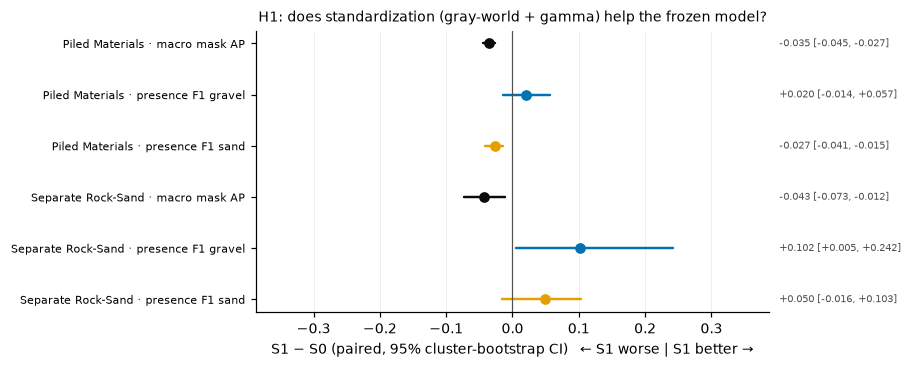

saved figure: outputs/04_holdout/figures/fig04_predictions_S0_vs_S1.png|pdf


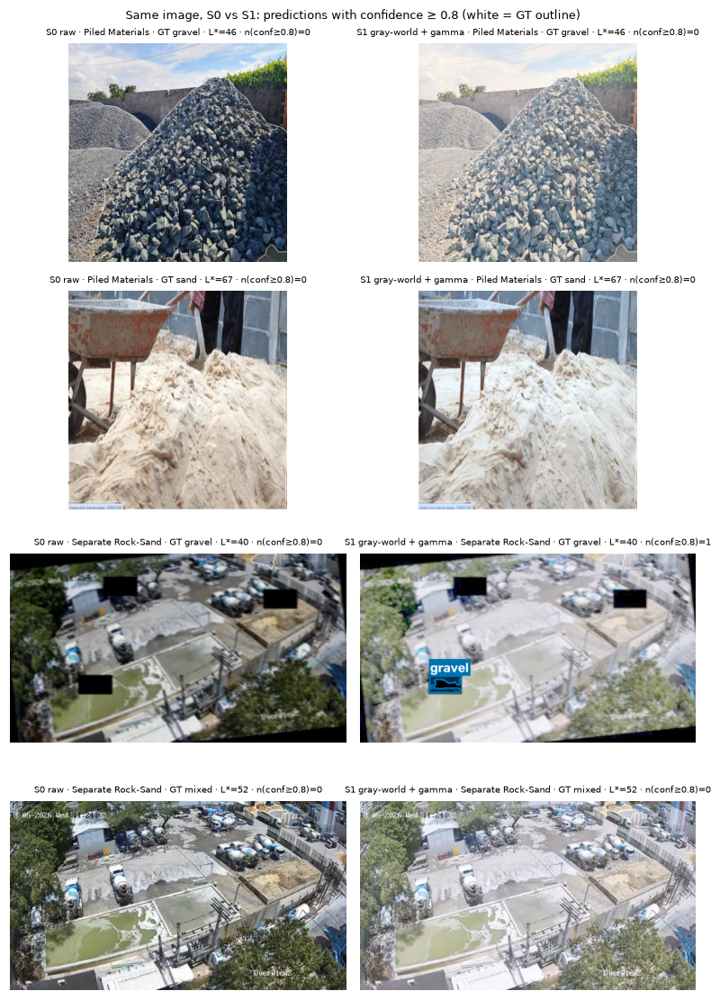

In [24]:
def paired_presence_delta(d, c, n_boot=1000):
    a = EVAL[(d, "S0_raw")]["l2df"][["image_id", "state", "group_merged", "pred_state"]]
    b = EVAL[(d, "S1_dev_stats")]["l2df"][["image_id", "pred_state"]]
    m = a.merge(b, on="image_id", suffixes=("_0", "_1"))
    y = m.state.isin([c, "mixed"]).values; p0 = m.pred_state_0.isin([c, "mixed"]).values; p1 = m.pred_state_1.isin([c, "mixed"]).values
    f = lambda ii: presence_metrics(y[ii], p1[ii])["F1"] - presence_metrics(y[ii], p0[ii])["F1"]
    rng = np.random.default_rng(SEED); groups = m.group_merged.unique(); by_g = {g: np.flatnonzero(m.group_merged.values == g) for g in groups}
    boot = [f(np.concatenate([by_g[g] for g in rng.choice(groups, len(groups))])) for _ in range(n_boot)]
    return f(np.arange(len(m))), *np.percentile(boot, [2.5, 97.5])

FR = []
for d in LABELLED:
    r = DIFF[DIFF.dataset == d].iloc[0]
    FR.append(dict(dataset=d, metric="macro mask AP", delta=r.delta_macro_mask_AP, ci_low=r.ci_low, ci_high=r.ci_high))
    for c in CLASS_NAMES:
        v, lo, hi = paired_presence_delta(d, c); FR.append(dict(dataset=d, metric=f"presence F1 {c}", delta=v, ci_low=lo, ci_high=hi))
FR = pd.DataFrame(FR); save_table(FR, TAB / "standardization_effects.csv")
display(FR.assign(dataset=FR.dataset.map(DS_LABEL)).set_index(["dataset", "metric"]).round(3))

fig, ax = plt.subplots(figsize=(8.4, 0.42 * len(FR) + 0.9))
yy = np.arange(len(FR))[::-1]
for yi, r in zip(yy, FR.itertuples()):
    col = CLASS_COLORS[r.metric.split()[-1]] if r.metric.startswith("presence") else INK
    ax.plot([r.ci_low, r.ci_high], [yi, yi], color=col, lw=1.6, solid_capstyle="round"); ax.scatter(r.delta, yi, s=36, color=col, zorder=3)
    ax.text(1.02, yi, f"{r.delta:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", va="center", fontsize=6.5, color=INK2, transform=ax.get_yaxis_transform())
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels([f"{DS_LABEL[r.dataset]} · {r.metric}" for r in FR.itertuples()], fontsize=7)
lim = max(abs(FR.ci_low).max(), abs(FR.ci_high).max()) * 1.6; ax.set_xlim(-lim, lim)
ax.set_xlabel("S1 − S0 (paired, 95% cluster-bootstrap CI)   ← S1 worse | S1 better →"); ax.grid(axis="y", visible=False)
ax.set_title("H1: does standardization (gray-world + gamma) help the frozen model?", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig12_standardization_effect"); plt.show()

ex = [(d, iid) for d in LABELLED for iid in [i for i in SAMPLE_HO if HO.loc[HO.image_id == i, "dataset"].iloc[0] == d][::2]]
fig, axes = plt.subplots(len(ex), 2, figsize=(7.2, 2.6 * len(ex)))
for k, (d, iid) in enumerate(ex):
    r = HO[HO.image_id == iid].iloc[0]; img = cv2.imread(r.path)
    for c_, sname in enumerate(STANDARD):
        im = img if STANDARD[sname] is None else STANDARD[sname](img)
        out, n_k = draw_pred(im, [x for x in EVAL[(d, sname)]["dets"] if x["image_id"] == iid], gt_iid=iid)
        axes[k, c_].imshow(out); clean_axes(axes[k, c_])
        axes[k, c_].set_title(f"{'S0 raw' if c_ == 0 else 'S1 gray-world + gamma'} · {DS_LABEL[d]} · GT {r.state} · L*={r.L_mean:.0f} · n(conf≥{VIS_CONF})={n_k}", fontsize=6.3)
fig.suptitle(f"Same image, S0 vs S1: predictions with confidence ≥ {VIS_CONF} (white = GT outline)", fontsize=8.5)
fig.tight_layout(); savefig(fig, FIG / "fig04_predictions_S0_vs_S1"); plt.show()

### 7.5 แบบจำลองมั่นใจผิดที่ใด (confidence ≥ 0.8)

**Method** แสดงผลการทำนายบนภาพ S0 เฉพาะ instance ที่ confidence ≥ 0.8 ด้วยพื้นสีและขอบของ mask, กรอบ และป้ายชื่อคลาส (gravel สีน้ำเงิน, sand สีส้ม) ป้ายไม่แสดงค่า confidence เพราะทุก instance ในรูปผ่านเกณฑ์ 0.8 แล้ว เส้นสีขาวคือขอบของ GT ภาพในรูปนี้**เลือกจากผล** คือสุ่มจากภาพที่มี detection ≥ 0.8 อย่างน้อยหนึ่งชิ้น cluster ละไม่เกินหนึ่งภาพ ชุดละ 8 ภาพ ด้วย seed 42 เพื่อดูลักษณะของการทำนายที่แบบจำลองมั่นใจสูง ทั้งที่ถูกและผิด ตารางแสดงจำนวนภาพที่มี detection ระดับนี้ในแต่ละชุด และรูปถัดไปแสดง precision, recall และ F1 ตลอดช่วง threshold

**Limitation** ค่า 0.8 เลือกเพื่อการแสดงผลหลังเปิด holdout จึงเป็นการวิเคราะห์ post-hoc ไม่แทน threshold ที่ตรึงไว้ (gravel 0.37, sand 0.28) และไม่ใช้เลือก threshold ใหม่

saved figure: outputs/04_holdout/figures/fig05_pred_conf08_piled_materials.png|pdf


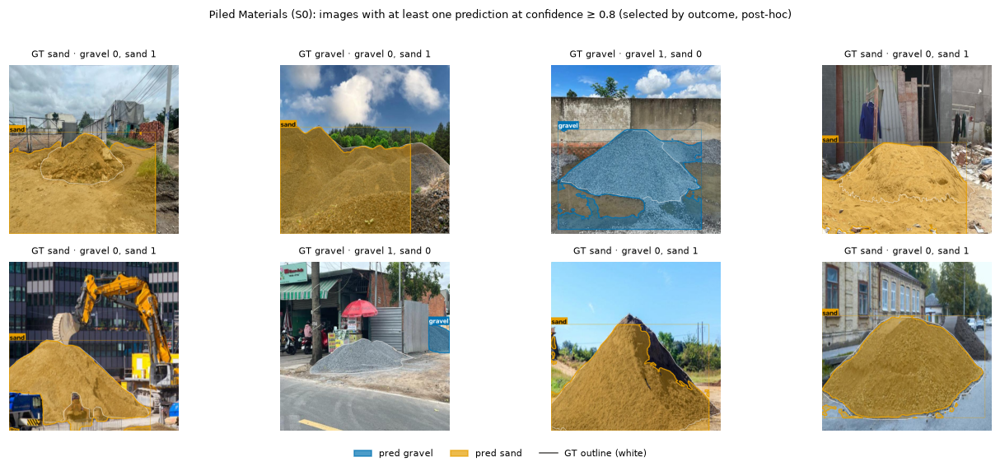

saved figure: outputs/04_holdout/figures/fig05_pred_conf08_separate_rock_sand.png|pdf


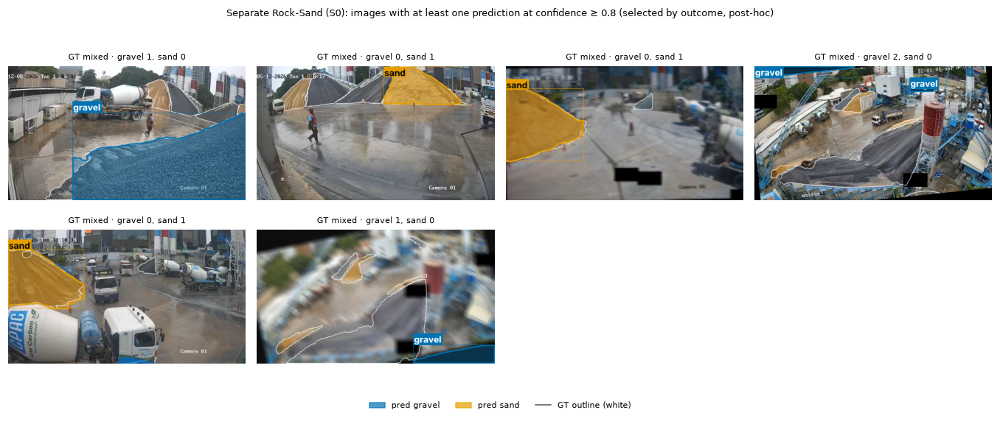

saved table: outputs/04_holdout/tables/conf08_coverage.csv (3 rows)


,images,images_with_conf_ge_08,share,max_conf
dataset,,,,
Piled Materials,1095,142,0.130,0.929
Separate Rock-Sand,182,16,0.088,0.904
S02 (unlabelled),66,0,0.000,0.661


In [25]:
CONF_ROWS = []
for d in list(LABELLED) + ["s02"]:
    dets = load_dets(d, "S0_raw"); by_img = defaultdict(list)
    for x in dets:
        by_img[x["image_id"]].append(x)
    sub = HO[HO.dataset == d]; hit = sub[sub.image_id.map(lambda i: any(x["score"] >= VIS_CONF for x in by_img[i]))]
    CONF_ROWS.append(dict(dataset=d, images=len(sub), images_with_conf_ge_08=len(hit), share=len(hit) / len(sub),
                          max_conf=max((x["score"] for x in dets), default=np.nan)))
    if hit.empty:
        continue
    ids = hit.sample(frac=1, random_state=SEED).drop_duplicates("cluster").head(8).image_id.tolist()
    nc = 4; nr = int(np.ceil(len(ids) / nc)); fig, axes = plt.subplots(nr, nc, figsize=(nc * 3.1, nr * 2.55), squeeze=False)
    for ax, iid in zip(axes.ravel(), ids):
        r = HO[HO.image_id == iid].iloc[0]
        im, _ = draw_pred(cv2.imread(r.path), by_img[iid], gt_iid=iid if d in GT_HO else None); ax.imshow(im); clean_axes(ax)
        n_c = Counter(CLASS_NAMES[x["category_id"] - 1] for x in by_img[iid] if x["score"] >= VIS_CONF)
        ax.set_title(f"GT {r.state if d in GT_HO else 'no label'} · gravel {n_c['gravel']}, sand {n_c['sand']}", fontsize=7)
    for ax in axes.ravel()[len(ids):]:
        ax.axis("off")
    fig.legend(handles=[Rectangle((0, 0), 1, 1, color=CLASS_COLORS["gravel"], alpha=0.7, label="pred gravel"),
                        Rectangle((0, 0), 1, 1, color=CLASS_COLORS["sand"], alpha=0.7, label="pred sand")]
                       + ([Line2D([], [], color=INK2, lw=1, label="GT outline (white)")] if d in GT_HO else []),
               loc="lower center", ncol=3, frameon=False, fontsize=7, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(f"{DS_LABEL[d]} (S0): images with at least one prediction at confidence ≥ {VIS_CONF} (selected by outcome, post-hoc)", fontsize=8.5)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97)); savefig(fig, FIG / f"fig05_pred_conf08_{d}"); plt.show()
CONF_T = pd.DataFrame(CONF_ROWS); save_table(CONF_T, TAB / "conf08_coverage.csv")
display(CONF_T.assign(dataset=CONF_T.dataset.map(DS_LABEL)).set_index("dataset").round(3))

saved table: outputs/04_holdout/tables/holdout_conf_sensitivity.csv (16 rows)


F1                   FP  \
threshold                                 frozen post_hoc_0.8  frozen   
dataset            standardization cls                                  
piled_materials    S0_raw          gravel  0.277        0.090   305.0   
                                   sand    0.286        0.101  1178.0   
separate_rock_sand S0_raw          gravel  0.095        0.059   126.0   
                                   sand    0.235        0.047    30.0   

                                                           TP               \
threshold                                 post_hoc_0.8 frozen post_hoc_0.8   
dataset            standardization cls                                       
piled_materials    S0_raw          gravel         27.0  133.0         26.0   
                                   sand           54.0  313.0         40.0   
separate_rock_sand S0_raw          gravel          3.0   21.0          9.0   
                                   sand            0.0   32.0          5.0   

                                          precision              recall  \
threshold                                    frozen post_hoc_0.8 frozen   
dataset            standardization cls                                    
piled_materials    S0_raw          gravel     0.304        0.491  0.254   
                                   sand       0.210        0.426  0.449   
separate_rock_sand S0_raw          gravel     0.143        0.750  0.072   
                                   sand       0.516        1.000  0.152   

                                                        
threshold                                 post_hoc_0.8  
dataset            standardization cls                  
piled_materials    S0_raw          gravel        0.050  
                                   sand          0.057  
separate_rock_sand S0_raw          gravel        0.031  
                                   sand          0.024

saved figure: outputs/04_holdout/figures/fig06_conf_sensitivity.png|pdf


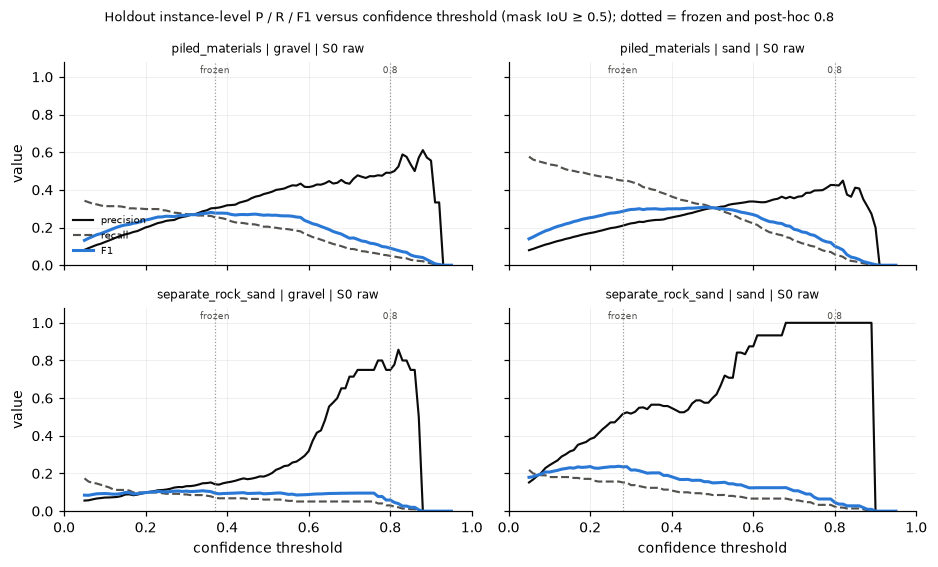

In [26]:
if EVAL:
    sens = []
    for (d, sname), e in EVAL.items():
        ids = e["R"].image_id.tolist()
        for i, c in enumerate(CLASS_NAMES):
            ths = {"frozen": FROZEN["conf_thresholds"][c], "post_hoc_0.8": VIS_CONF}
            for tag, th in ths.items():
                o = operating_point(e["res"]["segm"]["recs"], ids, i + 1, thresholds=[th]).iloc[0]
                sens.append(dict(dataset=d, standardization=sname, cls=c, threshold=tag, conf=th, **o.drop("conf").to_dict()))
    SENS = pd.DataFrame(sens); save_table(SENS, TAB / "holdout_conf_sensitivity.csv")
    display(SENS[SENS.standardization == "S0_raw"].pivot_table(index=["dataset", "standardization", "cls"], columns="threshold", values=["precision", "recall", "F1", "TP", "FP"]).round(3))

    ds_ = list(GT_HO); fig, axes = plt.subplots(len(ds_), 2, figsize=(8.6, 2.6 * len(ds_)), sharex=True, sharey=True, squeeze=False)
    PRF_INK = {"precision": "#0b0b0b", "recall": "#52514e", "F1": "#2a78d6"}; LS = {"precision": "-", "recall": "--", "F1": "-"}
    for a, d in enumerate(ds_):
        e = EVAL[(d, "S0_raw")]; ids = e["R"].image_id.tolist()
        for i, c in enumerate(CLASS_NAMES):
            ax = axes[a, i]; op = operating_point(e["res"]["segm"]["recs"], ids, i + 1)
            for m in ("precision", "recall", "F1"):
                ax.plot(op.conf, op[m], color=PRF_INK[m], ls=LS[m], lw=2 if m == "F1" else 1.4, label=m)
            for th, lab in ((FROZEN["conf_thresholds"][c], "frozen"), (VIS_CONF, "0.8")):
                ax.axvline(th, color="#999999", lw=0.8, ls=":"); ax.text(th, 1.02, lab, fontsize=6, ha="center", color="#52514e")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.08); ax.set_title(f"{d} | {c} | S0 raw", fontsize=8)
            ax.set_xlabel("confidence threshold" if a == len(ds_) - 1 else ""); ax.set_ylabel("value" if i == 0 else "")
    axes[0, 0].legend(frameon=False, fontsize=6.5, loc="lower left")
    fig.suptitle("Holdout instance-level P / R / F1 versus confidence threshold (mask IoU ≥ 0.5); dotted = frozen and post-hoc 0.8", fontsize=8.5)
    fig.tight_layout(); savefig(fig, FIG / "fig06_conf_sensitivity"); plt.show()

### 7.6 ชุด S02 (ไม่มี label) และการกระจายของ confidence

**Method** ชุด S02 ไม่มี annotation จึงเปรียบเทียบได้เพียงพฤติกรรมของแบบจำลอง รูปแสดง empirical CDF ของ confidence สูงสุดต่อภาพ (ภาพที่ไม่มี detection นับเป็น 0) ของชุด test และ holdout ทั้งสามชุดบนภาพ S0 เส้นที่อยู่ทางซ้ายหมายถึงแบบจำลองมั่นใจน้อยกว่า ตารางแสดงสัดส่วนของสถานะที่ทำนายบน S02

**การอ่านผล** การกระจายของ confidence ที่เลื่อนไปทางต่ำเป็นสัญญาณของ distribution shift ที่ตรวจได้โดยไม่ต้องมี label และอาจใช้เป็นเกณฑ์เตือนระหว่างการใช้งานจริง แต่ไม่บอกความถูกต้องของการทำนาย

saved figure: outputs/04_holdout/figures/fig13_confidence_ecdf.png|pdf


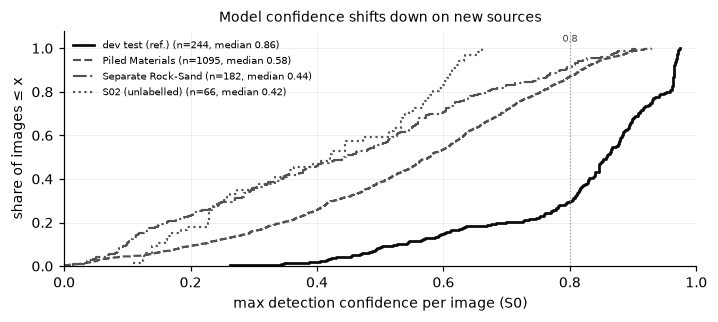

,n,frac_none,frac_gravel,frac_sand,frac_mixed,median_conf,dets_per_image
0,66,0.0,0.606,0.0,0.394,0.132,7.636


In [27]:
def max_conf_per_image(dets, ids):
    m = dict.fromkeys(map(int, ids), 0.0)
    for x in dets:
        if x["image_id"] in m:
            m[x["image_id"]] = max(m[x["image_id"]], x["score"])
    return np.sort(np.fromiter(m.values(), float))

MC = {"test": max_conf_per_image(DETS_TEST, TEST_IDS),
      **{d: max_conf_per_image(load_dets(d, "S0_raw"), HO[HO.dataset == d].image_id) for d in list(LABELLED) + ["s02"]}}
fig, ax = plt.subplots(figsize=(6.6, 3.0))
for (d, v), ls in zip(MC.items(), ("-", "--", "-.", ":")):
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=INK if d == "test" else INK2, ls=ls, lw=1.8 if d == "test" else 1.4,
            label=f"{DS_LABEL[d]} (n={len(v)}, median {np.median(v):.2f})")
for th, lab in ((VIS_CONF, "0.8"),):
    ax.axvline(th, color="#999999", lw=0.8, ls=":"); ax.text(th, 1.03, lab, fontsize=6.5, ha="center", color=INK2)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.08); ax.set_xlabel("max detection confidence per image (S0)"); ax.set_ylabel("share of images ≤ x")
ax.legend(frameon=False, fontsize=6.8, loc="upper left"); ax.set_title("Model confidence shifts down on new sources", fontsize=9)
fig.tight_layout(); savefig(fig, FIG / "fig13_confidence_ecdf"); plt.show()
display(S02[S02.standardization == "S0_raw"].drop(columns="standardization").round(3))

### 7.7 สรุปผลบนชุด holdout

ตารางแรกรวม metric หลักทุกตัวของทุกชุดและทุกเงื่อนไขภาพไว้ในตารางเดียว (บันทึกเป็น `holdout_eval_summary.csv`) โดยใช้ protocol scope (Notebook 03.5 หัวข้อ 3.0) และ threshold ที่ตรึงไว้ คอลัมน์แรกคือชุด test ของชุดพัฒนาซึ่งใช้เป็นค่าอ้างอิง P/R/F1 ระดับ instance ใช้ mask IoU ≥ 0.5 ที่ threshold ที่ตรึงไว้ (gravel 0.37, sand 0.28) ส่วน metric ระดับภาพใช้เกณฑ์ $\theta_c$ ที่ตรึงไว้ ตารางที่สองสรุปคำตอบของแต่ละคำถามในหัวข้อ 7.1–7.6 การอภิปรายและข้อจำกัดอยู่ในหัวข้อ 9

In [28]:
# ตารางสรุป eval: แถว = metric, คอลัมน์ = ชุดข้อมูล × เงื่อนไขภาพ (test ของชุดพัฒนาเป็นค่าอ้างอิง)
op_t = OP_TEST; l2_t = TEST_SUM["l2"]
cols = {"dev test (ref.)": None, **{f"{DS_LABEL[d]} · {s.split('_')[0]}": (d, s) for d in LABELLED for s in STANDARD}}
M = {}
for col, key in cols.items():
    if key is None:
        m = {**{k: pt[k] for k in ("mask_AP", "mask_AP50", "mask_AP75", "mask_APs", "mask_APm", "mask_APl", "mask_AP_gravel", "mask_AP_sand",
                                    "box_AP", "box_AP50", "box_AP75")},
             "mask_AP_ci": (tb["ci_low"], tb["ci_high"]), "n_images": l2_t["n"], "n_clusters": tb["n_clusters"],
             **{f"op_{c}_{k}": op_t[c][k] for c in CLASS_NAMES for k in ("precision", "recall", "F1")},
             "accuracy": l2_t["accuracy"], "balanced_accuracy": l2_t["balanced_accuracy"], "macro_F1": l2_t["macro_f1"],
             **{f"presence_F1_{c}": tf1[c] for c in CLASS_NAMES}}
    else:
        d, s = key; r = HOLD[(HOLD.dataset == d) & (HOLD.standardization == s)].iloc[0]
        o = OV[(OV.dataset == d) & (OV.standardization == s)].iloc[0]; p = PR_[(PR_.dataset == d) & (PR_.standardization == s)].set_index("material")
        m = {**{k: r[k] for k in ("mask_AP", "mask_AP50", "mask_AP75", "mask_APs", "mask_APm", "mask_APl", "mask_AP_gravel", "mask_AP_sand",
                                   "box_AP", "box_AP50", "box_AP75")},
             "mask_AP_ci": (r.mask_AP_macro_ci_low, r.mask_AP_macro_ci_high), "n_images": int(r.n), "n_clusters": EVAL[key]["boot"]["n_clusters"],
             **{f"op_{c}_{k}": r[f"op_{c}_{k}"] for c in CLASS_NAMES for k in ("precision", "recall", "F1")},
             "accuracy": o.accuracy, "balanced_accuracy": o.balanced_accuracy, "macro_F1": o.macro_F1,
             **{f"presence_F1_{c}": p.loc[c, "F1"] for c in CLASS_NAMES}}
    M[col] = m

ROWS = [("data", "images", "n_images"), ("data", "near-duplicate clusters", "n_clusters"),
        ("instance · mask", "AP50-95 (macro)", "mask_AP"), ("instance · mask", "AP50-95 95% CI", "mask_AP_ci"),
        ("instance · mask", "AP50", "mask_AP50"), ("instance · mask", "AP75", "mask_AP75"),
        ("instance · mask", "AP small / medium / large", ("mask_APs", "mask_APm", "mask_APl")),
        ("instance · mask", "AP50-95 gravel", "mask_AP_gravel"), ("instance · mask", "AP50-95 sand", "mask_AP_sand"),
        ("instance · box", "AP50-95", "box_AP"), ("instance · box", "AP50", "box_AP50"), ("instance · box", "AP75", "box_AP75"),
        *[(f"instance · frozen threshold · {c}", k, f"op_{c}_{k}") for c in CLASS_NAMES for k in ("precision", "recall", "F1")],
        ("image · 4 states", "accuracy", "accuracy"), ("image · 4 states", "balanced accuracy", "balanced_accuracy"),
        ("image · 4 states", "macro-F1", "macro_F1"),
        ("image · presence", "F1 gravel", "presence_F1_gravel"), ("image · presence", "F1 sand", "presence_F1_sand")]

def fmt(v):
    if isinstance(v, tuple):
        v = ["–" if (x is None or x < 0 or np.isnan(x)) else f"{x:.3f}" for x in v]
        return f"[{v[0]}, {v[1]}]" if len(v) == 2 else " / ".join(v)
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    return "–" if v is None or np.isnan(v) or v < 0 else f"{v:.3f}"

get = lambda m, k: tuple(m[x] for x in k) if isinstance(k, tuple) else m[k]
EVAL_SUM = pd.DataFrame({col: [fmt(get(m, k)) for _, _, k in ROWS] for col, m in M.items()},
                        index=pd.MultiIndex.from_tuples([(g, n) for g, n, _ in ROWS], names=["level", "metric"]))
save_table(EVAL_SUM.reset_index(), TAB / "holdout_eval_summary.csv")
display(EVAL_SUM)


saved table: outputs/04_holdout/tables/holdout_eval_summary.csv (23 rows)


dev test (ref.)  \
level                                metric                                         
data                                 images                                   244   
                                     near-duplicate clusters                    7   
instance · mask                      AP50-95 (macro)                        0.534   
                                     AP50-95 95% CI                [0.414, 0.772]   
                                     AP50                                   0.806   
                                     AP75                                   0.516   
                                     AP small / medium / large  – / 0.541 / 0.560   
                                     AP50-95 gravel                         0.638   
                                     AP50-95 sand                           0.430   
instance · box                       AP50-95                                0.540   
                                     AP50                                   0.734   
                                     AP75                                   0.617   
instance · frozen threshold · gravel precision                              0.885   
                                     recall                                 0.823   
                                     F1                                     0.853   
instance · frozen threshold · sand   precision                              0.667   
                                     recall                                 0.738   
                                     F1                                     0.700   
image · 4 states                     accuracy                               1.000   
                                     balanced accuracy                      1.000   
                                     macro-F1                               1.000   
image · presence                     F1 gravel                              1.000   
                                     F1 sand                                1.000   

                                                               Piled Materials · S0  \
level                                metric                                           
data                                 images                                   1,095   
                                     near-duplicate clusters                  1,031   
instance · mask                      AP50-95 (macro)                          0.075   
                                     AP50-95 95% CI                  [0.065, 0.093]   
                                     AP50                                     0.156   
                                     AP75                                     0.063   
                                     AP small / medium / large    – / 0.017 / 0.117   
                                     AP50-95 gravel                           0.071   
                                     AP50-95 sand                             0.080   
instance · box                       AP50-95                                  0.093   
                                     AP50                                     0.194   
                                     AP75                                     0.083   
instance · frozen threshold · gravel precision                                0.304   
                                     recall                                   0.254   
                                     F1                                       0.277   
instance · frozen threshold · sand   precision                                0.210   
                                     recall                                   0.449   
                                     F1                                       0.286   
image · 4 states                     accuracy                                 0.542   
                                     balanced accuracy                        0.346   
                          

In [29]:
h = HEAD.set_index("dataset"); fr = FR.set_index(["dataset", "metric"]); ct = CONF_T.set_index("dataset")
ANS = []
for d in LABELLED:
    ANS += [dict(question="7.1 drop vs test", dataset=DS_LABEL[d], finding=f"macro mask AP {h.loc[d, 'mask_AP']:.3f} [{h.loc[d, 'AP_ci_low']:.3f}, {h.loc[d, 'AP_ci_high']:.3f}] vs test {h.loc['test', 'mask_AP']:.3f}"),
            dict(question="7.2 image level", dataset=DS_LABEL[d], finding=f"presence F1 gravel {h.loc[d, 'F1_gravel']:.2f}, sand {h.loc[d, 'F1_sand']:.2f} (test {h.loc['test', 'F1_gravel']:.2f} / {h.loc['test', 'F1_sand']:.2f})"),
            dict(question="7.3 main error", dataset=DS_LABEL[d], finding=f"GT gravel → sand {g2s.get(d, 0):.0%}; GT gravel missed "
                 f"{float(OUTC[(OUTC.dataset == d) & (OUTC.side == 'GT') & (OUTC.cls == 'gravel') & (OUTC.outcome == 'missed')].share.sum()):.0%}; "
                 f"GT sand missed {float(OUTC[(OUTC.dataset == d) & (OUTC.side == 'GT') & (OUTC.cls == 'sand') & (OUTC.outcome == 'missed')].share.sum()):.0%}"),
            dict(question="7.4 S1 − S0", dataset=DS_LABEL[d], finding=f"Δ macro mask AP {fr.loc[(d, 'macro mask AP'), 'delta']:+.3f} [{fr.loc[(d, 'macro mask AP'), 'ci_low']:+.3f}, {fr.loc[(d, 'macro mask AP'), 'ci_high']:+.3f}]"),
            dict(question="7.5 conf ≥ 0.8", dataset=DS_LABEL[d], finding=f"{int(ct.loc[d, 'images_with_conf_ge_08'])}/{int(ct.loc[d, 'images'])} images have any detection ≥ 0.8")]
ANS.append(dict(question="7.6 S02", dataset=DS_LABEL["s02"], finding=f"max confidence {ct.loc['s02', 'max_conf']:.2f}; median per-image max {np.median(MC['s02']):.2f} vs test {np.median(MC['test']):.2f}"))
ANS = pd.DataFrame(ANS); save_table(ANS, TAB / "holdout_answers.csv")
with pd.option_context("display.max_colwidth", 200):
    display(ANS.set_index(["question", "dataset"]))

saved table: outputs/04_holdout/tables/holdout_answers.csv (11 rows)


,,finding
question,dataset,
7.1 drop vs test,Piled Materials,"macro mask AP 0.075 [0.065, 0.093] vs test 0.534"
7.2 image level,Piled Materials,"presence F1 gravel 0.54, sand 0.74 (test 1.00 / 1.00)"
7.3 main error,Piled Materials,GT gravel → sand 15%; GT gravel missed 59%; GT sand missed 54%
7.4 S1 − S0,Piled Materials,"Δ macro mask AP -0.035 [-0.045, -0.027]"
7.5 conf ≥ 0.8,Piled Materials,142/1095 images have any detection ≥ 0.8
7.1 drop vs test,Separate Rock-Sand,"macro mask AP 0.087 [0.044, 0.148] vs test 0.534"
7.2 image level,Separate Rock-Sand,"presence F1 gravel 0.42, sand 0.64 (test 1.00 / 1.00)"
7.3 main error,Separate Rock-Sand,GT gravel → sand 0%; GT gravel missed 93%; GT sand missed 85%
7.4 S1 − S0,Separate Rock-Sand,"Δ macro mask AP -0.043 [-0.073, -0.012]"


**การตีความ**

1. **ขนาดของการลดลง** macro mask AP (protocol scope) ลดจาก 0.534 บนชุด test เหลือ 0.075 (95% CI 0.065–0.093) บน Piled Materials และ 0.087 (0.044–0.148) บน Separate Rock-Sand ระดับภาพลดลงน้อยกว่า โดย F1 ของการตรวจพบ sand ยังอยู่ที่ 0.74 และ 0.64 แต่ F1 ของ gravel ลดเหลือ 0.54 และ 0.42 ผลนี้แสดงว่าแบบจำลองที่ตรึงไว้ยังไม่พร้อมใช้กับแหล่งภาพที่ต่างจากชุดพัฒนา
2. **ลักษณะของความผิดพลาด** สาเหตุหลักคือการตรวจไม่พบ (GT ไม่ถูกจับคู่ 54–93%) และ detection บนพื้นหลัง (48–86% ของ detection) มากกว่าการทายผิดคลาส การทาย gravel เป็น sand พบเพียง 15% ของ GT gravel ใน Piled Materials AP ของวัตถุขนาดกลางบน holdout ใกล้ศูนย์ (0.017 และ 0.008; วัตถุขนาดเล็กถูก ignore ภายใต้ protocol scope) แบบจำลองจึงยังจับได้เฉพาะกองวัสดุขนาดใหญ่ ซึ่งสอดคล้องกับ distribution shift ในหัวข้อ 4 มากกว่าปัญหาการ map คลาส Rock → gravel
3. **การทำภาพให้เป็นมาตรฐาน (H1)** S1 ทำให้ macro mask AP ลดลงอย่างมีนัยสำคัญในทั้งสองชุด (−0.035 และ −0.043, CI ไม่คร่อมศูนย์) แม้ F1 ของการตรวจพบ gravel ใน Separate Rock-Sand จะเพิ่มขึ้น 0.10 (CI 0.005–0.242) ผลรวมจึงไม่สนับสนุน H1 การปรับสีและความสว่างอย่างเดียวไม่สามารถชดเชยความต่างของมุมกล้อง ระยะ และลักษณะของฉากได้
4. **ความมั่นใจของแบบจำลอง** ค่ามัธยฐานของ confidence สูงสุดต่อภาพลดจาก 0.86 บนชุด test เหลือ 0.42–0.58 บน holdout และภาพที่มี detection ≥ 0.8 มีเพียง 13% (Piled Materials), 9% (Separate Rock-Sand) และ 0% (S02) การเลื่อนของการกระจายนี้ตรวจได้โดยไม่ต้องมี label จึงอาจใช้เป็นตัวเตือนเมื่อระบบถูกใช้กับภาพที่อยู่นอกโดเมนของการฝึก

## 8. วิดีโอ: จากภาพนิ่งสู่สถานะตามเวลา

ระบบใช้งานจริงรับภาพต่อเนื่องจากกล้อง ส่วนนี้จึงแสดงว่าแบบจำลองที่ตรึงไว้ให้สถานะที่ต่อเนื่องและเปลี่ยนตามเหตุการณ์หรือไม่ ลำดับของส่วนนี้คือ เตรียมวิดีโอและ contact sheet (8.0) → แปลงวิดีโอเป็นผลการทำนาย, overlay และ GIF (8.1) → timeline ของคะแนนและสถานะ (8.2) → protocol การประเมินระดับเวลาเมื่อมี label ที่ยืนยันแล้ว (8.3)

**ความสัมพันธ์กับชุดพัฒนา** คลิป `0a48349e` (sand) และ `5d81688a` (gravel) อยู่ในกลุ่มของ test จึงไม่ถูกใช้ฝึก ส่วน `32842c3f` ไม่อยู่ในชุดพัฒนาเลย

### 8.0 การเตรียมวิดีโอ

คัดลอกวิดีโอ 3 คลิปจาก `experiment/data/thesis_videos/` พร้อม SHA-256 และตัดเฟรมทุก 0.5 วินาทีเป็น contact sheet สำหรับการร่าง label ระดับเวลา

In [30]:
TEMP = OUT_ROOT / "temporal"; (TEMP / "contact_sheets").mkdir(parents=True, exist_ok=True)
VID_DIR = ROOT / "data" / "videos"; VID_DIR.mkdir(parents=True, exist_ok=True)
VIDS = {}
for p in sorted(VIDEOS_SRC.glob("*.mp4")):
    dst = VID_DIR / p.name
    if not dst.exists():
        shutil.copy2(p, dst)
    cap = cv2.VideoCapture(str(dst)); fps = cap.get(cv2.CAP_PROP_FPS); n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
    VIDS[p.stem[:8]] = dict(path=str(dst), sha256=sha256_file(dst), fps=fps, frames=n, duration_s=n / fps,
                            in_dev_split=MANIFEST.loc[MANIFEST.group_merged.str.startswith(p.stem[:8]), "split"].unique().tolist())
(TEMP / "videos.json").write_text(json.dumps(VIDS, indent=2)); display(pd.DataFrame(VIDS).T)

for vid, v in VIDS.items():
    sheet = TEMP / "contact_sheets" / f"{vid}.png"
    if sheet.exists():
        continue
    cap = cv2.VideoCapture(v["path"]); ts = np.arange(0, v["duration_s"], 0.5); frames = []
    for t in ts:
        cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000); ok, fr = cap.read()
        if ok:
            frames.append((t, fr))
    cap.release()
    nc = 10; nr = int(np.ceil(len(frames) / nc))
    fig, axes = plt.subplots(nr, nc, figsize=(nc * 1.6, nr * 1.9))
    for ax, (t, fr) in zip(axes.ravel(), frames):
        ax.imshow(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB)); ax.set_title(f"{t:.1f}s", fontsize=6)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f"{vid}: frames every 0.5 s (for drafting state labels)", fontsize=8); fig.tight_layout(); fig.savefig(sheet, dpi=110); plt.close(fig)
print("contact sheets:", sorted(p.name for p in (TEMP / "contact_sheets").iterdir()))

,path,sha256,fps,frames,duration_s,in_dev_split
0a48349e,/home/supawich/Desktop/Aggregate_Project/imple...,87c643c1cd8e08f1f05649ab5a5bfb1889839003817c9b...,29.981982,1664,55.5,[test]
32842c3f,/home/supawich/Desktop/Aggregate_Project/imple...,460d3cb7553aa910b1d0a3d29f7e0d20b18d5113fefed1...,29.997479,595,19.835,[]
5d81688a,/home/supawich/Desktop/Aggregate_Project/imple...,5e1553d98c4b489e0aab9f22b5ff21a6dee1d4d6b03fdf...,30.0,623,20.766667,[]


contact sheets: ['0a48349e.png', '32842c3f.png', '5d81688a.png']


### 8.1 วิดีโอ → ผลการทำนาย → overlay และ GIF

**Method** รันแบบจำลองและ preprocessing ที่ตรึงไว้ทุก 3 เฟรม (ประมาณ 10 เฟรมต่อวินาที) คำนวณคะแนน $S_c$ ของแต่ละเฟรมด้วยสูตรเดียวกับระดับภาพ แล้วกำหนดสถานะด้วยเกณฑ์ $\theta_c$ ที่ตรึงไว้ (raw) และสถานะที่ทำให้เรียบด้วย EMA (α = 0.3) กับ hysteresis แบบ k-of-n (k = 3, n = 5) ซึ่งกำหนดไว้ล่วงหน้า ภาพ overlay แสดง mask, กรอบ และป้าย `class conf` ของทุก instance ของ gravel (สีน้ำเงิน) และ sand (สีส้ม) ที่ confidence ไม่น้อยกว่าเกณฑ์ที่ตรึงไว้ของแต่ละคลาส แถบด้านบนแสดงสถานะของเฟรม และแถบด้านล่างแสดง timeline ตลอดคลิป GIF จำกัดไว้ไม่เกิน 90 เฟรมต่อคลิป เล่นเร็ว 2 เท่า และกว้าง 400 พิกเซลเพื่อให้อ่านป้ายได้โดยคุมขนาดของ notebook ส่วนวิดีโอ overlay ความละเอียดเต็มบันทึกใน `outputs/04_holdout/temporal/`

**Limitation** ยังไม่มี label ระดับเวลาที่ยืนยันแล้ว ส่วนนี้จึงรายงานเฉพาะลำดับสถานะที่ทำนาย ไม่ได้วัดความถูกต้อง


=== 0a48349e (0a48349e-f671-436a-8af5-de54f079109f.mp4) | 1664 frames @ 30.0 fps = 55.5 s | predicted every 3 frames (555 predictions)
stage sequence (smoothed): none -> sand
     0.0 –    0.2 s   (  0.2 s)   none
     0.2 –   55.5 s   ( 55.3 s)   sand
time share: {'none': 0.004, 'gravel': 0.0, 'sand': 0.996, 'mixed': 0.0} | state switches raw 0, smoothed 1
saved: outputs/04_holdout/temporal/pred_overlay_0a48349e.mp4 | outputs/04_holdout/temporal/pred_overlay_0a48349e.gif (10.2 MB, every 21 video frames, 2x speed)


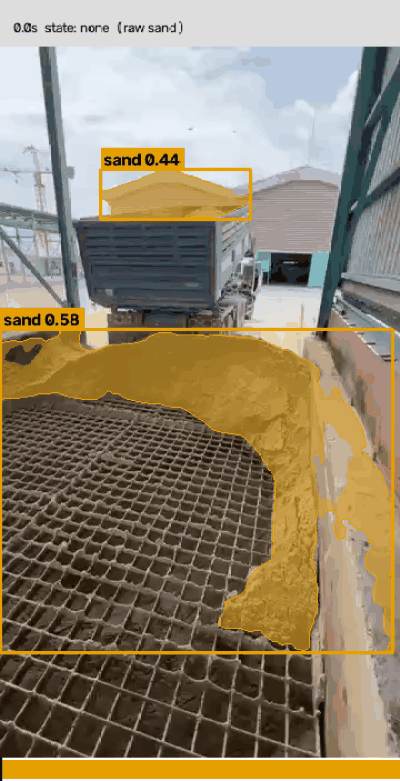


=== 32842c3f (32842c3f-25ad-4bab-8eb5-89fc619a6918.mp4) | 595 frames @ 30.0 fps = 19.8 s | predicted every 3 frames (199 predictions)
stage sequence (smoothed): none -> gravel -> mixed -> gravel -> mixed -> gravel -> mixed -> gravel
     0.0 –    0.2 s   (  0.2 s)   none
     0.2 –    3.3 s   (  3.1 s)   gravel
     3.3 –    3.8 s   (  0.5 s)   mixed
     3.8 –   13.6 s   (  9.8 s)   gravel
    13.6 –   13.9 s   (  0.3 s)   mixed
    13.9 –   15.6 s   (  1.7 s)   gravel
    15.6 –   16.2 s   (  0.6 s)   mixed
    16.2 –   19.9 s   (  3.7 s)   gravel
time share: {'none': 0.01, 'gravel': 0.92, 'sand': 0.0, 'mixed': 0.07} | state switches raw 8, smoothed 7
saved: outputs/04_holdout/temporal/pred_overlay_32842c3f.mp4 | outputs/04_holdout/temporal/pred_overlay_32842c3f.gif (6.2 MB, every 9 video frames, 2x speed)


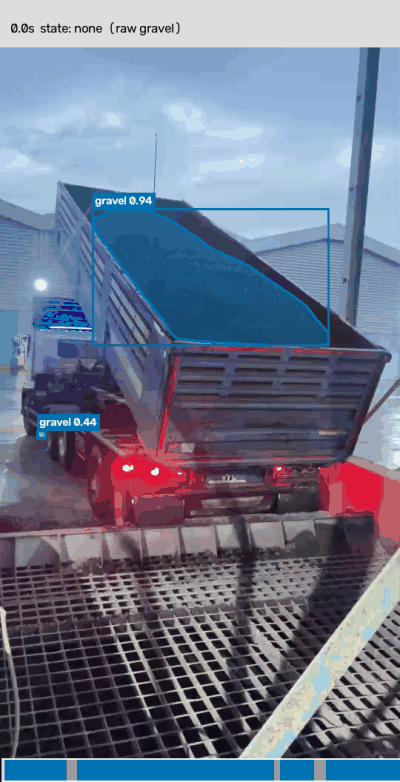


=== 5d81688a (5d81688a-7f52-42a4-b81d-822c2d2319a3.mp4) | 623 frames @ 30.0 fps = 20.8 s | predicted every 3 frames (208 predictions)
stage sequence (smoothed): none -> gravel
     0.0 –    0.2 s   (  0.2 s)   none
     0.2 –   20.8 s   ( 20.6 s)   gravel
time share: {'none': 0.01, 'gravel': 0.99, 'sand': 0.0, 'mixed': 0.0} | state switches raw 2, smoothed 1
saved: outputs/04_holdout/temporal/pred_overlay_5d81688a.mp4 | outputs/04_holdout/temporal/pred_overlay_5d81688a.gif (3.8 MB, every 9 video frames, 2x speed)


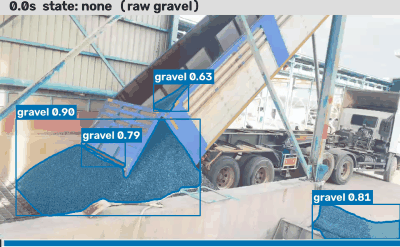

saved table: outputs/04_holdout/tables/video_state_summary.csv (3 rows)


,video,duration_s,n_pred,sequence,n_segments,switches_raw,switches_smoothed,share_none,share_gravel,share_sand,share_mixed
0,0a48349e,55.500,555,none -> sand,2,0,1,0.004,0.00,0.996,0.00
1,32842c3f,19.835,199,none -> gravel -> mixed -> gravel -> mixed -> ...,8,8,7,0.010,0.92,0.000,0.07
2,5d81688a,20.767,208,none -> gravel,2,2,1,0.010,0.99,0.000,0.00


In [31]:
# วิดีโอ -> prediction ทุก 3 เฟรม -> overlay + GIF + ลำดับสถานะ
import yaml as _yaml
from PIL import Image as PILImage
from IPython.display import Image as IPyImage, display
from ultralytics import YOLO

FROZEN_V = _yaml.safe_load((ROOT / "configs" / "frozen_inference.yaml").read_text())
W_V = ROOT / FROZEN_V["weights"]; assert sha256_file(W_V) == FROZEN_V["weights_sha256"], "checkpoint does not match frozen config"
def _unsharp_v(img, sigma=1.0, amount=0.5):
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)
PP_V = {None: None, "P5_unsharp": _unsharp_v, "P3_gamma_auto": _gamma_auto_frozen, "P1_grayworld": std_grayworld, "P2_clahe": _clahe,
        "P4_nlmeans": _denoise}[FROZEN_V.get("preprocessing")]
IMGSZ_V = int(FROZEN_V.get("imgsz", 640))
TH_V = np.array([FROZEN_V["state_thresholds"]["gravel"], FROZEN_V["state_thresholds"]["sand"]])
CONF_V = FROZEN_V["conf_thresholds"]; MINC_V = FROZEN_V.get("state_min_conf", 0.05)
STEP, GIF_EVERY, GIF_W, GIF_MAX_FRAMES = 3, 2, 400, 90   # GIF กว้างพอให้อ่านป้าย class conf ได้
EMA_A, KN = 0.3, (3, 5)
BGR = {"gravel": (178, 114, 0), "sand": (0, 159, 230), "mixed": (153, 153, 153), "none": (221, 221, 221)}

def presence_to_state(g, s):
    return "mixed" if g and s else "gravel" if g else "sand" if s else "none"

def smooth(S):
    ema = np.zeros_like(S); hist = [[], []]; cur = [False, False]; out = []
    for t in range(len(S)):
        ema[t] = S[t] if t == 0 else EMA_A * S[t] + (1 - EMA_A) * ema[t - 1]
        for c in range(2):
            hist[c] = (hist[c] + [ema[t, c] >= TH_V[c]])[-KN[1]:]
            if not cur[c] and sum(hist[c]) >= KN[0]:
                cur[c] = True
            elif cur[c] and (len(hist[c]) - sum(hist[c])) >= KN[0]:
                cur[c] = False
        out.append(presence_to_state(*cur))
    return out

def runs_of(states, ts):
    segs, s0 = [], 0
    for i in range(1, len(states) + 1):
        if i == len(states) or states[i] != states[s0]:
            segs.append((states[s0], ts[s0], ts[i] if i < len(states) else ts[-1] + STEP / FPS_)); s0 = i
    return segs

vmodel = YOLO(str(W_V)); VTEMP = OUT_ROOT / "temporal"; VTEMP.mkdir(parents=True, exist_ok=True)
VID_SUM = []
for vp in sorted((ROOT / "data" / "videos").glob("*.mp4")):
    vid = vp.stem[:8]; cap = cv2.VideoCapture(str(vp)); FPS_ = cap.get(cv2.CAP_PROP_FPS); n_fr = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames, masks, boxes, S, ts = [], [], [], [], []
    k = 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if k % STEP == 0:
            img = PP_V(fr) if PP_V else fr
            out = vmodel.predict(img, imgsz=IMGSZ_V, conf=MINC_V, max_det=100, retina_masks=True, verbose=False)[0]
            s = np.zeros(2); ov = np.zeros((*fr.shape[:2], 2), bool); bx = []
            if out.masks is not None and len(out.boxes):
                md_ = out.masks.data.cpu().numpy() > 0.5
                for m_, c, cf, xyxy in zip(md_, out.boxes.cls.cpu().numpy().astype(int), out.boxes.conf.cpu().numpy(), out.boxes.xyxy.cpu().numpy()):
                    if m_.shape != fr.shape[:2]:
                        m_ = cv2.resize(m_.astype(np.uint8), (fr.shape[1], fr.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
                    s[c] += cf * m_.mean()
                    if cf >= CONF_V[CLASS_NAMES[c]]:
                        ov[..., c] |= m_; bx.append((xyxy, c, float(cf)))
            frames.append(fr); masks.append(ov); boxes.append(bx); S.append(s); ts.append(k / FPS_)
        k += 1
    cap.release()
    S = np.asarray(S); ts = np.asarray(ts)
    raw = [presence_to_state(g, s_) for g, s_ in zip(S[:, 0] >= TH_V[0], S[:, 1] >= TH_V[1])]
    sm = smooth(S)
    # overlay และ timeline
    H0, W0 = frames[0].shape[:2]; bar_h = max(14, H0 // 30)
    tl = np.full((bar_h, W0, 3), 255, np.uint8)
    for x in range(W0):
        tl[2:-2, x] = BGR[sm[min(int(x / W0 * len(sm)), len(sm) - 1)]]
    canv = []
    for j, (fr, ov) in enumerate(zip(frames, masks)):
        im = fr.copy()
        for c, name in enumerate(CLASS_NAMES):
            if ov[..., c].any():
                col = np.array(BGR[name], np.uint8)
                im[ov[..., c]] = (0.55 * im[ov[..., c]] + 0.45 * col).astype(np.uint8)
                cs, _ = cv2.findContours(ov[..., c].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(im, cs, -1, tuple(int(v) for v in col), max(1, W0 // 270))
        lw_, fs_ = max(2, W0 // 400), max(0.5, W0 / 1100)
        for xyxy, c, cf in sorted(boxes[j], key=lambda z: z[2]):   # กรอบและป้าย 'class conf' (conf สูงวาดทับด้านบน)
            col = BGR[CLASS_NAMES[c]]; x0, y0, x1, y1 = map(int, xyxy); lab = f"{CLASS_NAMES[c]} {cf:.2f}"
            cv2.rectangle(im, (x0, y0), (x1, y1), col, lw_)
            (tw, th), bl = cv2.getTextSize(lab, cv2.FONT_HERSHEY_SIMPLEX, fs_, lw_); ty = y0 if y0 - th - bl - 4 >= 0 else y0 + th + bl + 4
            cv2.rectangle(im, (x0, ty - th - bl - 4), (x0 + tw + 6, ty), col, -1)
            cv2.putText(im, lab, (x0 + 3, ty - bl - 2), cv2.FONT_HERSHEY_SIMPLEX, fs_, (255, 255, 255) if c == 0 else (0, 0, 0), lw_, cv2.LINE_AA)
        top = np.full((bar_h * 2, W0, 3), BGR[sm[j]], np.uint8)
        cv2.putText(top, f"{ts[j]:5.1f}s  state: {sm[j]}  (raw {raw[j]})", (6, int(bar_h * 1.4)), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.4, W0 / 900), (0, 0, 0), max(1, W0 // 400), cv2.LINE_AA)
        b = tl.copy(); xc = int(j / len(sm) * W0); cv2.line(b, (xc, 0), (xc, bar_h), (0, 0, 0), max(2, W0 // 200))
        canv.append(np.vstack([top, im, b]))
    mp4 = VTEMP / f"pred_overlay_{vid}.mp4"
    wr = cv2.VideoWriter(str(mp4), cv2.VideoWriter_fourcc(*"mp4v"), FPS_ / STEP, (canv[0].shape[1], canv[0].shape[0]))
    for c_ in canv:
        wr.write(c_)
    wr.release()
    gif = VTEMP / f"pred_overlay_{vid}.gif"; scale = GIF_W / canv[0].shape[1]
    every = max(GIF_EVERY, int(np.ceil(len(canv) / GIF_MAX_FRAMES)))   # จำกัดจำนวนเฟรมของ GIF เพื่อคุมขนาด notebook
    gframes = [PILImage.fromarray(cv2.cvtColor(cv2.resize(c_, (GIF_W, int(c_.shape[0] * scale)), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB))
               .quantize(colors=128, method=PILImage.Quantize.MEDIANCUT) for c_ in canv[::every]]
    gframes[0].save(gif, save_all=True, append_images=gframes[1:], duration=int(1000 * STEP * every / FPS_ / 2), loop=0, optimize=True)
    # ลำดับสถานะ
    segs = runs_of(sm, ts)
    print(f"\n=== {vid} ({vp.name}) | {n_fr} frames @ {FPS_:.1f} fps = {n_fr / FPS_:.1f} s | predicted every {STEP} frames ({len(ts)} predictions)")
    print(f"stage sequence (smoothed): {' -> '.join(s for s, _, _ in segs)}")
    for s_, a, b_ in segs:
        print(f"  {a:6.1f} – {b_:6.1f} s   ({b_ - a:5.1f} s)   {s_}")
    frac = pd.Series(sm).value_counts(normalize=True).reindex(STATES, fill_value=0)
    nsw_raw = sum(r1 != r0 for r0, r1 in zip(raw[:-1], raw[1:])); nsw_sm = len(segs) - 1
    print("time share:", {k_: round(float(v), 3) for k_, v in frac.items()}, f"| state switches raw {nsw_raw}, smoothed {nsw_sm}")
    print(f"saved: {mp4.relative_to(ROOT)} | {gif.relative_to(ROOT)} ({gif.stat().st_size / 1e6:.1f} MB, every {every * STEP} video frames, 2x speed)")
    display(IPyImage(filename=str(gif)))
    VID_SUM.append(dict(video=vid, duration_s=n_fr / FPS_, n_pred=len(ts), sequence=" -> ".join(s for s, _, _ in segs), n_segments=len(segs),
                        switches_raw=nsw_raw, switches_smoothed=nsw_sm, **{f"share_{k_}": float(v) for k_, v in frac.items()}))
    pd.DataFrame(dict(t_s=ts, S_gravel=S[:, 0], S_sand=S[:, 1], state_raw=raw, state_smoothed=sm)).to_csv(VTEMP / f"pred_states_{vid}.csv", index=False)
    del frames, masks, boxes, canv, gframes
VID_SUM = pd.DataFrame(VID_SUM); save_table(VID_SUM, TAB / "video_state_summary.csv"); display(VID_SUM.round(3))

### 8.2 Timeline ของคะแนนและสถานะ

**Method** แสดงคะแนน $S_{gravel}$ และ $S_{sand}$ ของทุกเฟรมที่ทำนาย พร้อมเกณฑ์ $\theta_c$ ที่ตรึงไว้ (เส้นประ) และแถบสถานะหลังทำให้เรียบ เพื่อดูว่าการเปลี่ยนสถานะเกิดจากคะแนนที่ข้ามเกณฑ์อย่างชัดเจนหรือจากคะแนนที่แกว่งรอบเกณฑ์

saved figure: outputs/04_holdout/figures/fig14_video_timelines.png|pdf


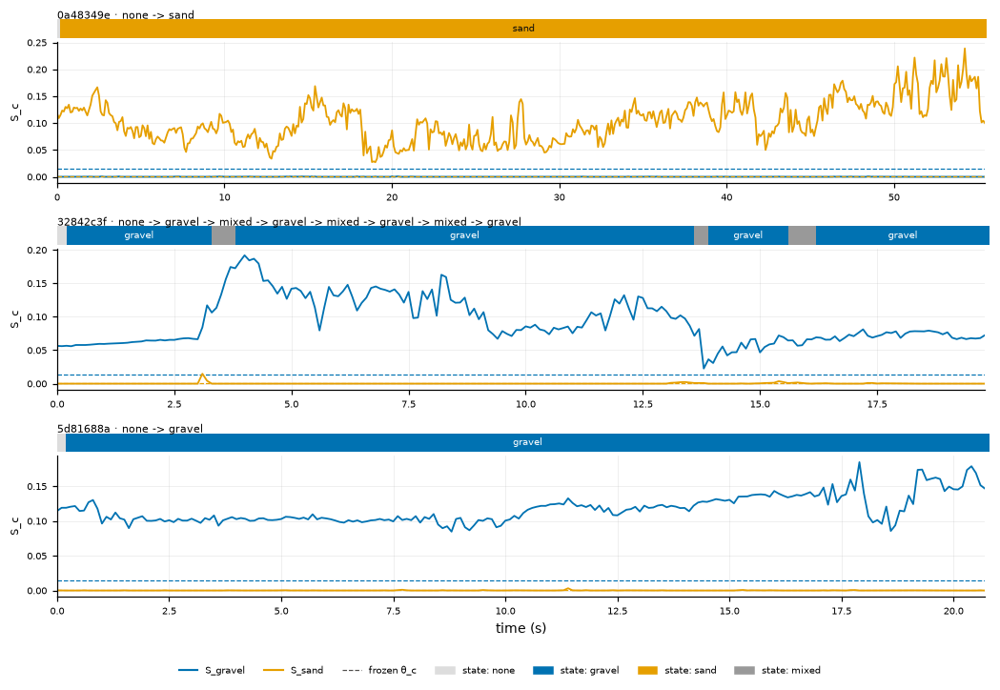

In [32]:
vids = VID_SUM.video.tolist()
fig, axes = plt.subplots(len(vids), 1, figsize=(9.6, 2.0 * len(vids) + 0.5))
for ax, vid in zip(np.atleast_1d(axes), vids):
    ts_df = pd.read_csv(VTEMP / f"pred_states_{vid}.csv"); T = ts_df.t_s.values
    dt = np.diff(T, append=T[-1] + (T[1] - T[0] if len(T) > 1 else 0.1)); tr = ax.get_xaxis_transform()
    for t0, w, s_ in zip(T, dt, ts_df.state_smoothed):   # แถบสถานะเหนือกราฟ (y ในพิกัดของแกน)
        ax.add_patch(Rectangle((t0, 1.03), w, 0.13, transform=tr, color=CLASS_COLORS[s_], lw=0, clip_on=False))
    for s_, a, b_ in runs_of(ts_df.state_smoothed.tolist(), T.tolist()):
        if b_ - a > 0.06 * T[-1]:
            ax.text((a + b_) / 2, 1.095, s_, transform=tr, ha="center", va="center", fontsize=6.5, color="white" if s_ == "gravel" else INK)
    for c, th in zip(CLASS_NAMES, TH_V):
        ax.plot(T, ts_df[f"S_{c}"], color=CLASS_COLORS[c], lw=1.2)
        ax.axhline(th, color=CLASS_COLORS[c], lw=0.8, ls="--")
    ax.set_xlim(0, T[-1]); ax.set_ylabel("S_c", fontsize=7); ax.tick_params(labelsize=6.5)
    ax.set_title(f"{vid} · {VID_SUM.set_index('video').loc[vid, 'sequence']}", fontsize=7.5, loc="left", pad=16)
np.atleast_1d(axes)[-1].set_xlabel("time (s)")
fig.legend(handles=[Line2D([], [], color=CLASS_COLORS[c], lw=1.4, label=f"S_{c}") for c in CLASS_NAMES]
                   + [Line2D([], [], color=INK2, lw=0.8, ls="--", label="frozen θ_c")]
                   + [Rectangle((0, 0), 1, 1, color=CLASS_COLORS[s], label=f"state: {s}") for s in STATES],
           loc="lower center", ncol=7, frameon=False, fontsize=6.5, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.04, 1, 1)); savefig(fig, FIG / "fig14_video_timelines"); plt.show()

### 8.3 Protocol การประเมินระดับเวลา (L3)

ส่วนนี้จะรันเมื่อมี label ระดับเวลาที่ผู้วิจัยยืนยันแล้ว (`RUN_TEMPORAL_EVAL = True`)

1. **ร่าง label (draft_v0):** ผู้ช่วยวิจัยกำหนดช่วงเวลา (`clip, t_start, t_end, state`) จาก contact sheet ในหัวข้อ 8.0 **ก่อน** ดูผลการทำนายบนวิดีโอ และบันทึกเป็น `manifests/temporal_labels_draft_v0.csv`
2. สร้างวิดีโอที่แสดง timeline ของ label ร่าง (ไม่มี prediction) ให้ผู้วิจัยตรวจทาน แล้วบันทึกฉบับที่ยืนยันเป็น `manifests/temporal_labels_v1.csv` (ด่าน G5 ของ L3)
3. ใช้คะแนนและการทำให้เรียบชุดเดียวกับหัวข้อ 8.1 โดยไม่ปรับพารามิเตอร์จากผลบนวิดีโอ
4. วัด frame-wise accuracy, segmental F1@{10, 25, 50} และ Edit score (Lea et al., 2017; Abu Farha & Gall, 2019), จำนวนครั้งที่สถานะเปลี่ยนต่อนาที, เวลาตั้งแต่ GT เปลี่ยนสถานะจนการทำนายเปลี่ยนตาม และความถูกต้องรายคลิปพร้อม Wilson interval

**Limitation** มีเพียง 3 คลิป และ label จัดทำโดยผู้ช่วยวิจัยและยืนยันโดยผู้วิจัยคนเดียว ผลจึงเป็นหลักฐานเชิงสาธิต ไม่ใช่การประเมินเชิงสถิติ

In [33]:
DRAFT = ROOT / "manifests" / "temporal_labels_draft_v0.csv"
V1 = ROOT / "manifests" / "temporal_labels_v1.csv"
STATE_COLORS_BGR = {s: tuple(int(255 * c) for c in matplotlib.colors.to_rgb(CLASS_COLORS[s])[::-1]) for s in STATES}

def labels_at(df, vid, t):
    m = df[(df.clip == vid) & (df.t_start <= t) & (t < df.t_end)]
    return m.state.iloc[0] if len(m) else "none"

def render_review_video(labels, vid, out_path, pred=None):
    # แถบ timeline คำนวณครั้งเดียวต่อวิดีโอ แล้ววาดตำแหน่งเวลาปัจจุบันทับในแต่ละเฟรม
    v = VIDS[vid]; cap = cv2.VideoCapture(v["path"]); fps = v["fps"]; W_, H_ = int(cap.get(3)), int(cap.get(4)); T = v["duration_s"]
    srcs = [labels] + ([pred] if pred is not None else []); bar = 40
    state_at = lambda src, t: labels_at(src, vid, t) if isinstance(src, pd.DataFrame) else src(t)
    bars = []
    for src in srcs:
        b = np.full((bar, W_, 3), 255, np.uint8)
        for x in range(W_):
            b[4:bar - 14, x] = STATE_COLORS_BGR[state_at(src, x / W_ * T)]
        bars.append(b)
    wr = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (W_, H_ + bar * len(srcs)))
    k = 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        t = k / fps; canvas = np.vstack([fr] + [b.copy() for b in bars])
        for row, src in enumerate(srcs):
            y0 = H_ + row * bar; xc = int(t / T * W_)
            cv2.line(canvas, (xc, y0), (xc, y0 + bar), (0, 0, 0), 2)
            cv2.putText(canvas, ("label: " if row == 0 else "pred: ") + state_at(src, t), (5, y0 + bar - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 1)
        wr.write(canvas); k += 1
    cap.release(); wr.release()

if DRAFT.exists():
    D0 = pd.read_csv(DRAFT); display(D0)
    for vid in VIDS:
        out = TEMP / f"review_draft_{vid}.mp4"
        if not out.exists():
            render_review_video(D0, vid, out)
    print("review videos:", sorted(p.name for p in TEMP.glob("review_draft_*.mp4")))
else:
    print(f"draft labels not yet written: {DRAFT.relative_to(ROOT)} (columns: clip,t_start,t_end,state,note)")

draft labels not yet written: manifests/temporal_labels_draft_v0.csv (columns: clip,t_start,t_end,state,note)


In [34]:
def segments(seq):
    segs, start = [], 0
    for i in range(1, len(seq) + 1):
        if i == len(seq) or seq[i] != seq[start]:
            segs.append((seq[start], start, i)); start = i
    return segs

def edit_score(pred, gt):
    a, b = [s[0] for s in segments(pred)], [s[0] for s in segments(gt)]
    D = np.zeros((len(a) + 1, len(b) + 1)); D[:, 0] = range(len(a) + 1); D[0, :] = range(len(b) + 1)
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (a[i - 1] != b[j - 1]))
    return (1 - D[-1, -1] / max(len(a), len(b))) * 100

def segmental_f1(pred, gt, k):
    P, G = segments(pred), segments(gt); used = np.zeros(len(G), bool); tp = fp = 0
    for lab, s, e in P:
        ious = [((min(e, ge) - max(s, gs)) / (max(e, ge) - min(s, gs))) if gl == lab and min(e, ge) > max(s, gs) else 0 for gl, gs, ge in G]
        j = int(np.argmax(ious)) if ious else -1
        if j >= 0 and ious[j] >= k and not used[j]:
            tp += 1; used[j] = True
        else:
            fp += 1
    fn = int((~used).sum()); p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return 2 * p * r / max(p + r, 1e-9) * 100

EMA_ALPHA, K_OF_N = 0.3, (3, 5)
def smooth_states(S, th):
    ema = np.zeros_like(S); pres = np.zeros_like(S, bool); hist = [[], []]; cur = [False, False]
    for t in range(len(S)):
        ema[t] = S[t] if t == 0 else EMA_ALPHA * S[t] + (1 - EMA_ALPHA) * ema[t - 1]
        for c in range(2):
            hist[c] = (hist[c] + [ema[t, c] >= th[c]])[-K_OF_N[1]:]
            if not cur[c] and sum(hist[c]) >= K_OF_N[0]:
                cur[c] = True
            elif cur[c] and (len(hist[c]) - sum(hist[c])) >= K_OF_N[0]:
                cur[c] = False
            pres[t, c] = cur[c]
    return states_from_presence(pres[:, 0], pres[:, 1])

if RUN_TEMPORAL_EVAL:
    assert V1.exists(), "G5 (L3): ต้องมี label ที่ผู้วิจัยยืนยันแล้ว"
    L1_ = pd.read_csv(V1); model = YOLO(str(W)); th = [FROZEN["state_thresholds"]["gravel"], FROZEN["state_thresholds"]["sand"]]
    rows, tl = [], []
    for vid, v in VIDS.items():
        cap = cv2.VideoCapture(v["path"]); fps = v["fps"]; k = 0; S, ts = [], []
        tf = pipeline(None)
        while True:
            ok, fr = cap.read()
            if not ok:
                break
            if k % 3 == 0:
                img = tf(fr) if tf else fr
                out = model.predict(img, imgsz=IMGSZ_F, conf=STATE_MIN_CONF, max_det=100, retina_masks=True, verbose=False)[0]
                s = np.zeros(2)
                if out.masks is not None:
                    area = out.masks.data.cpu().numpy().reshape(len(out.boxes), -1).mean(1)
                    for c, cf, a in zip(out.boxes.cls.cpu().numpy().astype(int), out.boxes.conf.cpu().numpy(), area):
                        s[c] += cf * a
                S.append(s); ts.append(k / fps)
            k += 1
        cap.release()
        S = np.asarray(S); ts = np.asarray(ts)
        raw = states_from_presence(S[:, 0] >= th[0], S[:, 1] >= th[1]); sm = smooth_states(S, th)
        gt = np.asarray([labels_at(L1_, vid, t) for t in ts])
        for name, pred in (("raw", raw), ("smoothed", sm)):
            sw = int((pred[1:] != pred[:-1]).sum())
            gt_change = [ts[i] for i in range(1, len(gt)) if gt[i] != gt[i - 1]]
            lat = [next((ts[j] - t0 for j in range(len(ts)) if ts[j] >= t0 and pred[j] == gt[j]), np.nan) for t0 in gt_change]
            rows.append(dict(clip=vid, decision=name, frames=len(ts), frame_acc=float((pred == gt).mean()), edit=edit_score(list(pred), list(gt)),
                             **{f"F1@{int(k*100)}": segmental_f1(list(pred), list(gt), k) for k in (0.10, 0.25, 0.50)},
                             switches_per_min=sw / (v["duration_s"] / 60), time_to_correct_s_median=float(np.nanmedian(lat)) if lat else np.nan,
                             clip_majority_correct=Counter(pred[pred != "none"]).most_common(1)[0][0] == Counter(gt[gt != "none"]).most_common(1)[0][0]
                             if (pred != "none").any() and (gt != "none").any() else False))
        tl.append(pd.DataFrame(dict(clip=vid, t=ts, S_gravel=S[:, 0], S_sand=S[:, 1], gt=gt, pred_raw=raw, pred_smoothed=sm)))
        lab_fn = lambda t, ts=ts, sm=sm: sm[min(np.searchsorted(ts, t), len(sm) - 1)]
        render_review_video(L1_, vid, TEMP / f"result_{vid}.mp4", pred=lab_fn)
    TEMPR = pd.DataFrame(rows); save_table(TEMPR, TAB / "temporal_results.csv"); save_table(pd.concat(tl), TAB / "temporal_timelines.csv")
    from statsmodels.stats.proportion import proportion_confint
    sm_ = TEMPR[TEMPR.decision == "smoothed"]; k = int(sm_.clip_majority_correct.sum()); n = len(sm_)
    print(f"clip-level correct: {k}/{n}, Wilson 95% CI {proportion_confint(k, n, method='wilson')}")
    display(TEMPR.round(3))

## 9. สรุป การอภิปราย ข้อจำกัด และงานในอนาคต

ส่วนนี้เขียนหลังรันครบ โดยอ้างตัวเลขจาก `outputs/04_holdout/tables/` เท่านั้น และครอบคลุมหัวข้อต่อไปนี้

1. **Distribution shift (หัวข้อ 4):** ระยะห่างของสถิติภาพ (`distribution_shift_stats.csv`) และ AUC ของ domain classifier (`domain_classifier_auc.csv`)
2. **Generalization (RQ9, หัวข้อ 7.1–7.3):** `holdout_headline.csv`, `image_level_presence.csv`, `instance_outcomes.csv` และสรุปใน `holdout_answers.csv`
3. **ผลของการทำภาพให้เป็นมาตรฐาน (RQ11, หัวข้อ 7.4):** `standardization_effects.csv`
4. **ความมั่นใจของแบบจำลองบนแหล่งภาพใหม่ (หัวข้อ 7.5–7.6):** `conf08_coverage.csv`, `holdout_conf_sensitivity.csv` และ `fig13_confidence_ecdf` โดยระบุว่าค่า 0.8 เป็นการวิเคราะห์ post-hoc
5. **ระดับเวลา (หัวข้อ 8):** `video_state_summary.csv`, GIF และ `fig14_video_timelines`
6. **ข้อจำกัด:** holdout เคยถูกประเมินโดยงานเดิม; การ map คลาส Rock → gravel; ไม่มีข้อมูลการถ่ายภาพหรือแผ่นเทียบสี; label ช่วงเวลามีผู้ตรวจคนเดียว; ชุดพัฒนามาจากสถานที่และกล้องจำนวนจำกัด; ชุด test มีเพียง 7 cluster
7. **ข้อเสนอสำหรับการใช้งานและงานในอนาคต:** ขั้นตอนการถ่ายภาพในหัวข้อ 6.1, การเก็บข้อมูลของโดเมนเป้าหมายเพื่อฝึกเพิ่ม, การเฝ้าระวังการกระจายของ confidence ระหว่างใช้งาน, label ระดับเวลาจากผู้ตรวจหลายคน และการวัด latency บน Raspberry Pi 5 ในสภาพการทำงานจริง